# ISO V4 Sample-Flag Cut Fraction Analysis

This notebook focuses only on sample-flag cut columns and keeps the workflow compact.
The first code cell loads the SQLite table, computes per-step sample-cut fractions, builds summary tables, and renders histogram grids at wafer-band, band, and global levels.

Loaded rows with total_samples > 0: 70581
Output directory: /scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/analysis/sample_flag_percentages
Sample-flag columns: ['smurfgaps', 'turnaround_flags', 'jumps_slow', 'jumps_2pi', 'glitches_pre_hwpss', 'source_flags', 'glitches_post_hwpss', 'noisy_subscan_flags']

0) Total flagged percent across all sample-cut steps:
   sum(flagged_samples) / total_samples = 18.638%

1) Weighted percent per step by wafer-band (total at left)


/tmp/ipykernel_341776/2416669098.py:83: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series(weighted_percent_summary(g)))
/tmp/ipykernel_341776/2416669098.py:91: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series(weighted_percent_summary(g)))


,wafer,band,pct_all_flagged,pct_smurfgaps,pct_turnaround_flags,pct_jumps_slow,pct_jumps_2pi,pct_glitches_pre_hwpss,pct_source_flags,pct_glitches_post_hwpss,pct_noisy_subscan_flags
0,ws0,f090,16.859920,0.926886,6.547805,4.290326e-07,0.000523,0.000923,0.074289,0.012428,9.297066
2,ws1,f090,20.247124,0.057719,6.301310,1.117307e-06,0.000431,0.000500,0.040675,0.014247,13.832241
4,ws2,f090,17.808106,0.083565,6.299095,9.057731e-07,0.000353,0.000470,0.054859,0.016499,11.353265
6,ws3,f090,18.179586,0.032386,6.391082,3.738415e-06,0.000321,0.000731,0.036419,0.012708,11.705935
8,ws4,f090,20.564578,2.654073,6.235781,0.000000e+00,0.000335,0.000465,0.027358,0.013357,11.633210
10,ws5,f090,19.986124,1.440329,6.331248,4.297269e-06,0.000569,0.001637,0.041348,0.014430,12.156558
12,ws6,f090,18.140936,1.561870,6.252802,2.774875e-06,0.000522,0.000866,0.053907,0.014377,10.256588
1,ws0,f150,17.665779,0.945804,6.629085,9.853102e-06,0.000431,0.000228,0.079481,0.013935,9.996805
3,ws1,f150,20.447165,0.068134,6.865383,3.616126e-06,0.000519,0.000263,0.039913,0.012868,13.460082
5,ws2,f150,18.894627,0.063646,6.694416,2.734407e-06,0.000456,0.000515,0.043744,0.014521,12.077326



2) Weighted percent per step by band (all wafers combined, total at left)


,band,pct_all_flagged,pct_smurfgaps,pct_turnaround_flags,pct_jumps_slow,pct_jumps_2pi,pct_glitches_pre_hwpss,pct_source_flags,pct_glitches_post_hwpss,pct_noisy_subscan_flags
0,f090,18.462924,0.933494,6.359041,0.000002,0.000451,0.000802,0.051517,0.01390,11.103717
1,f150,18.741931,0.719076,6.598931,0.000004,0.000470,0.000370,0.053928,0.01435,11.354801



3) Weighted percent per step for all bands and wafers combined (total at left)


,group,pct_all_flagged,pct_smurfgaps,pct_turnaround_flags,pct_jumps_slow,pct_jumps_2pi,pct_glitches_pre_hwpss,pct_source_flags,pct_glitches_post_hwpss,pct_noisy_subscan_flags
0,all_wafers_all_bands,18.638445,0.798605,6.509954,0.000003,0.000463,0.00053,0.053034,0.014183,11.261672


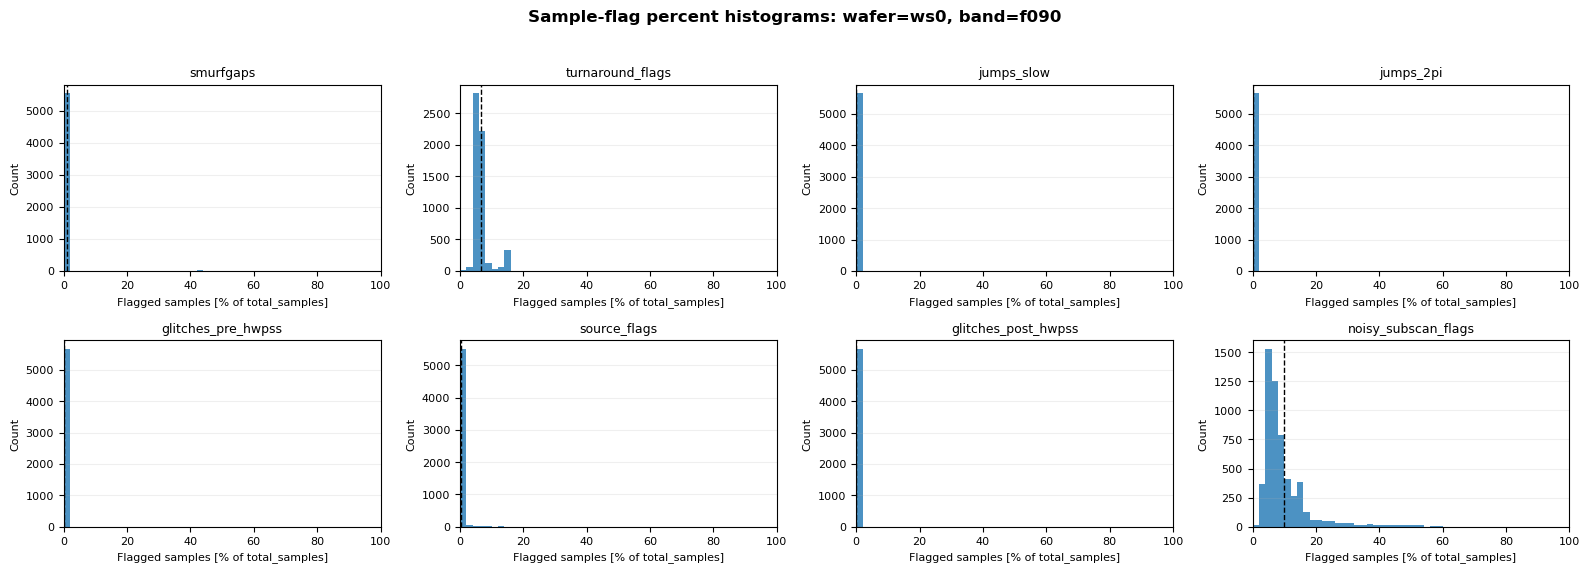

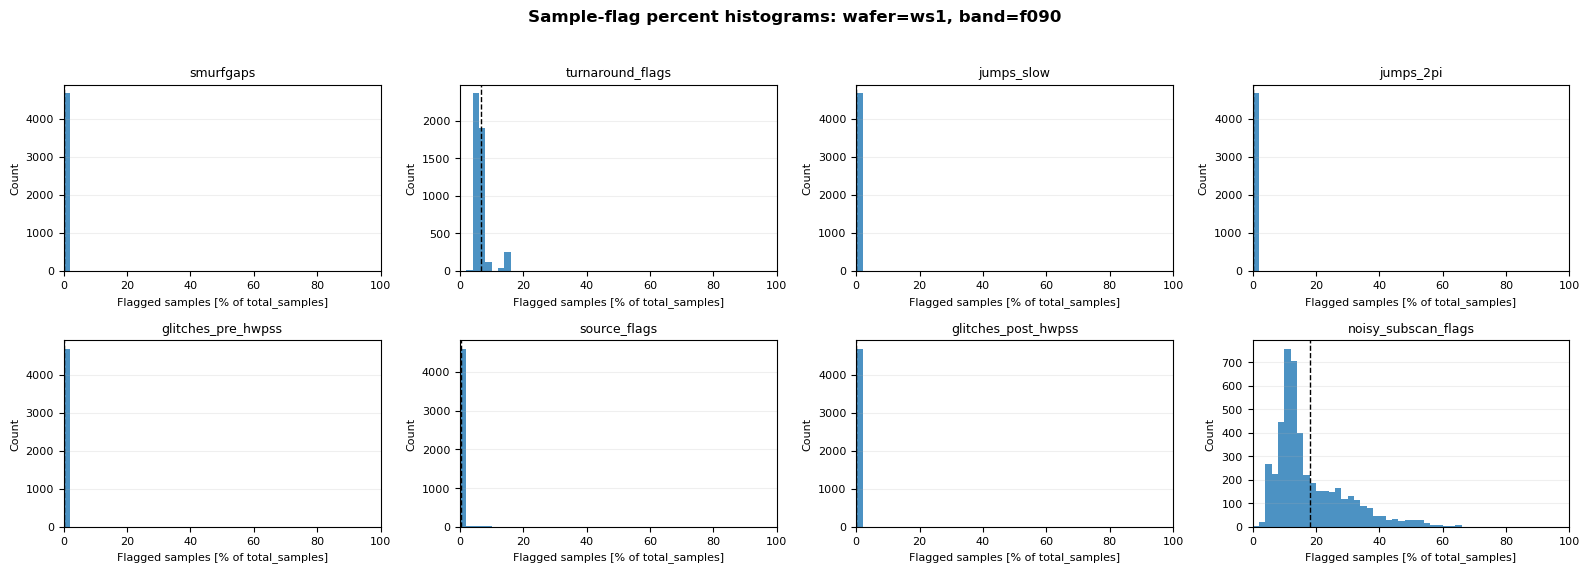

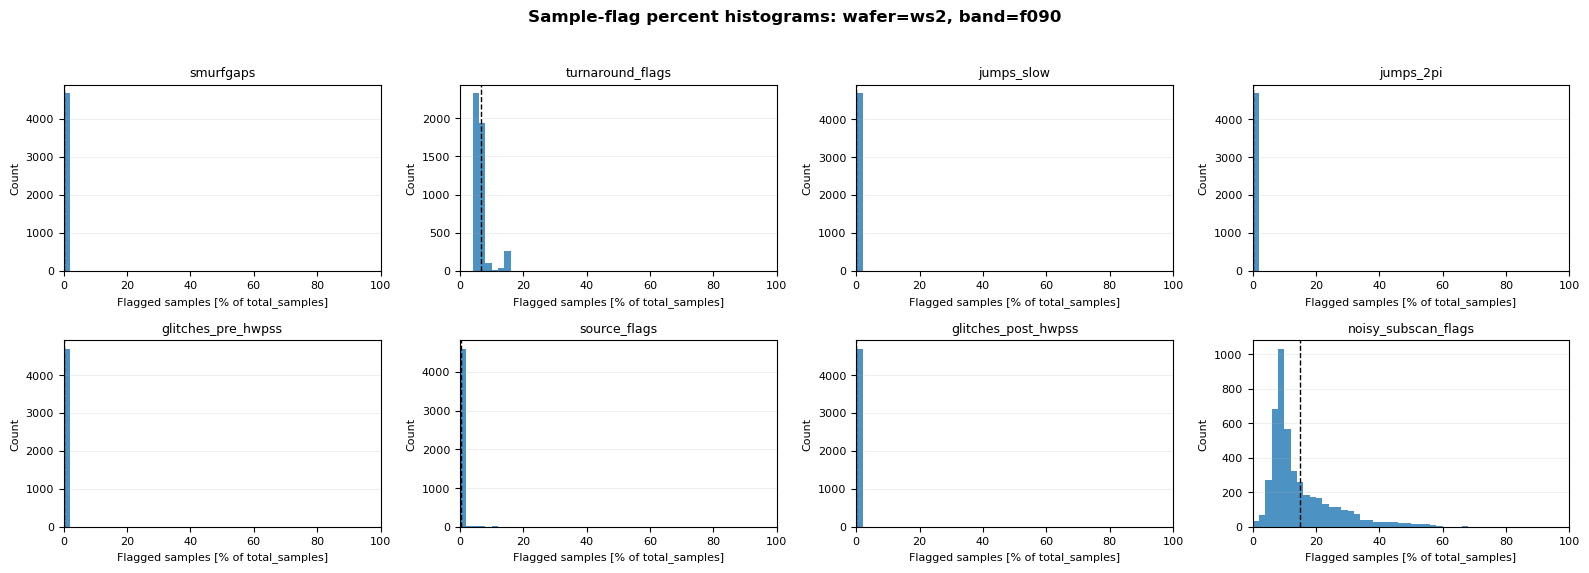

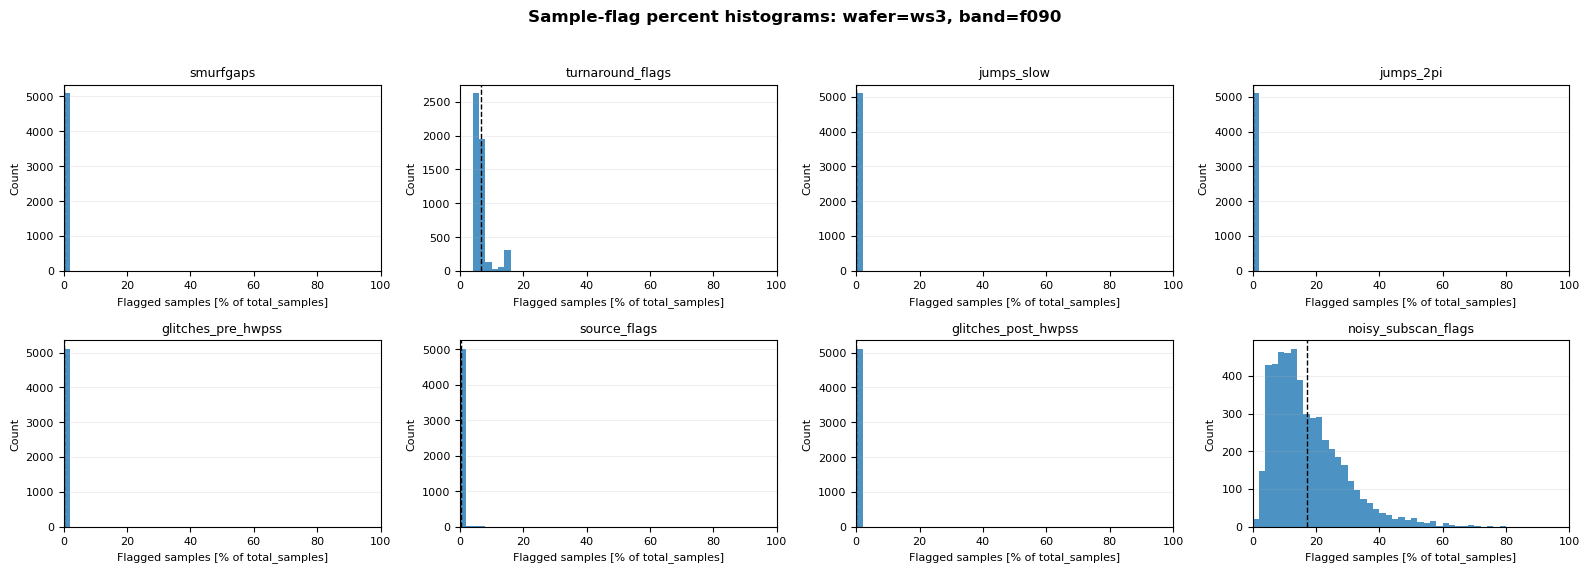

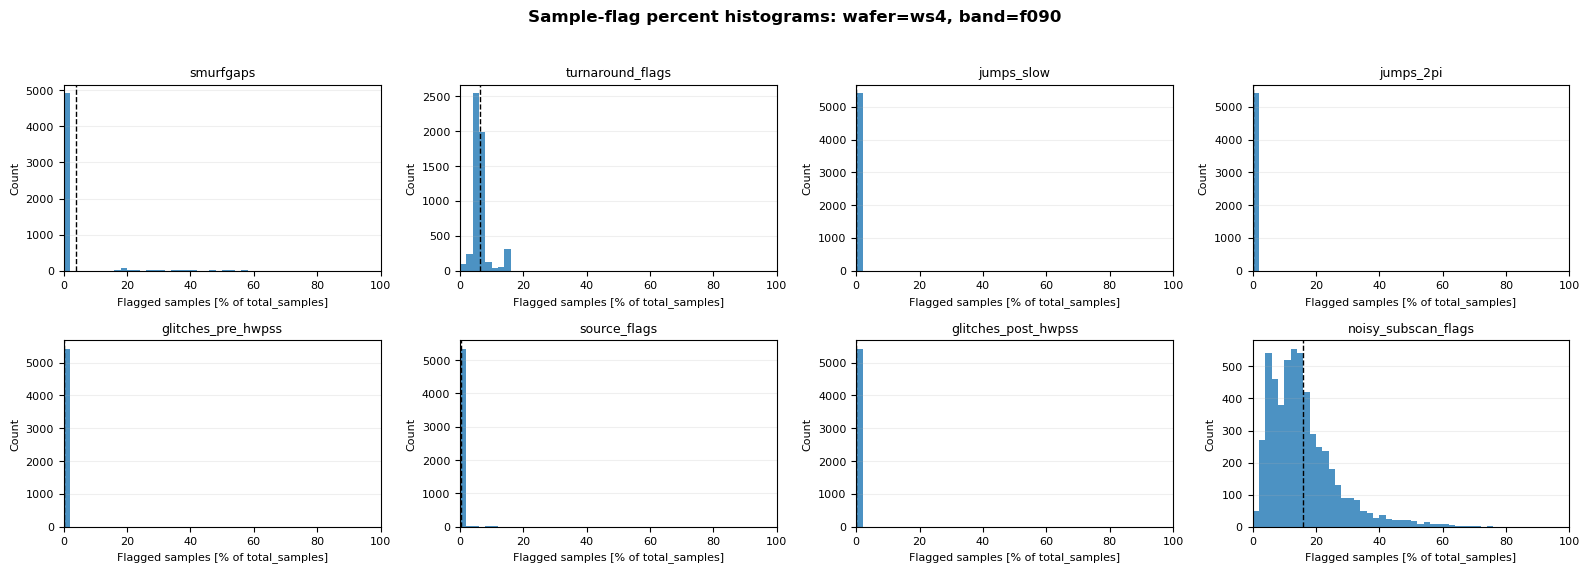

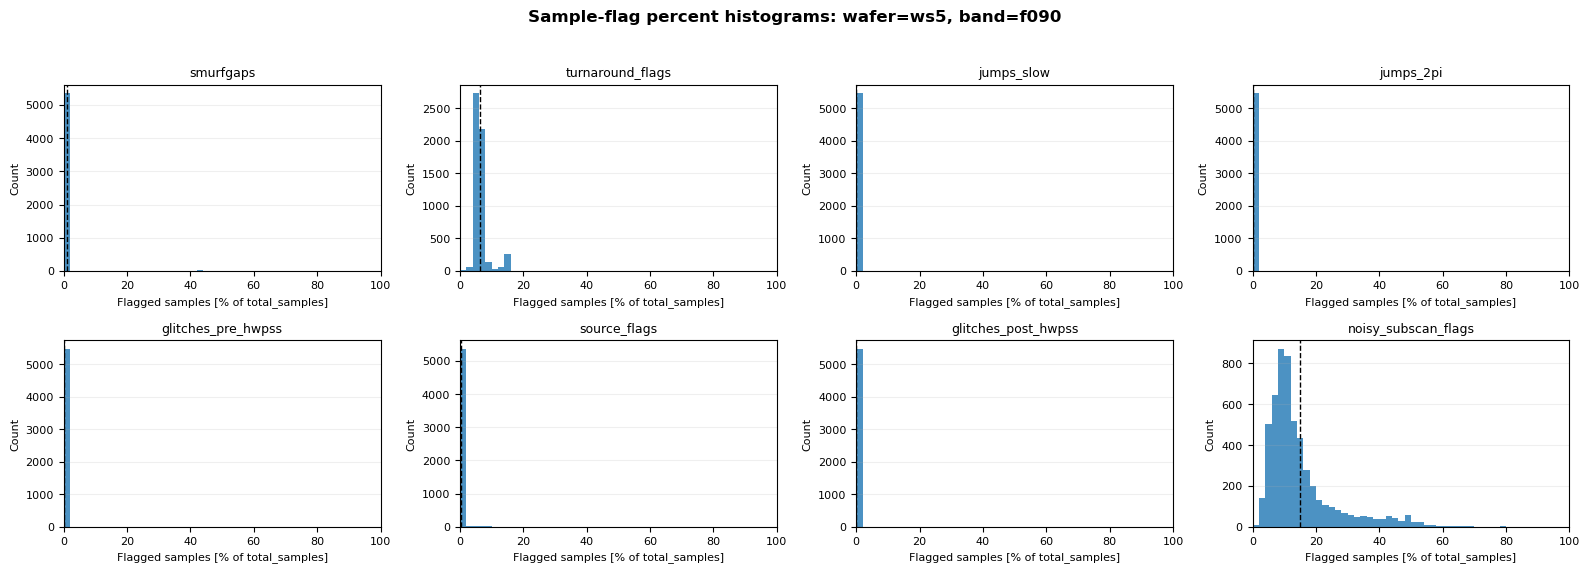

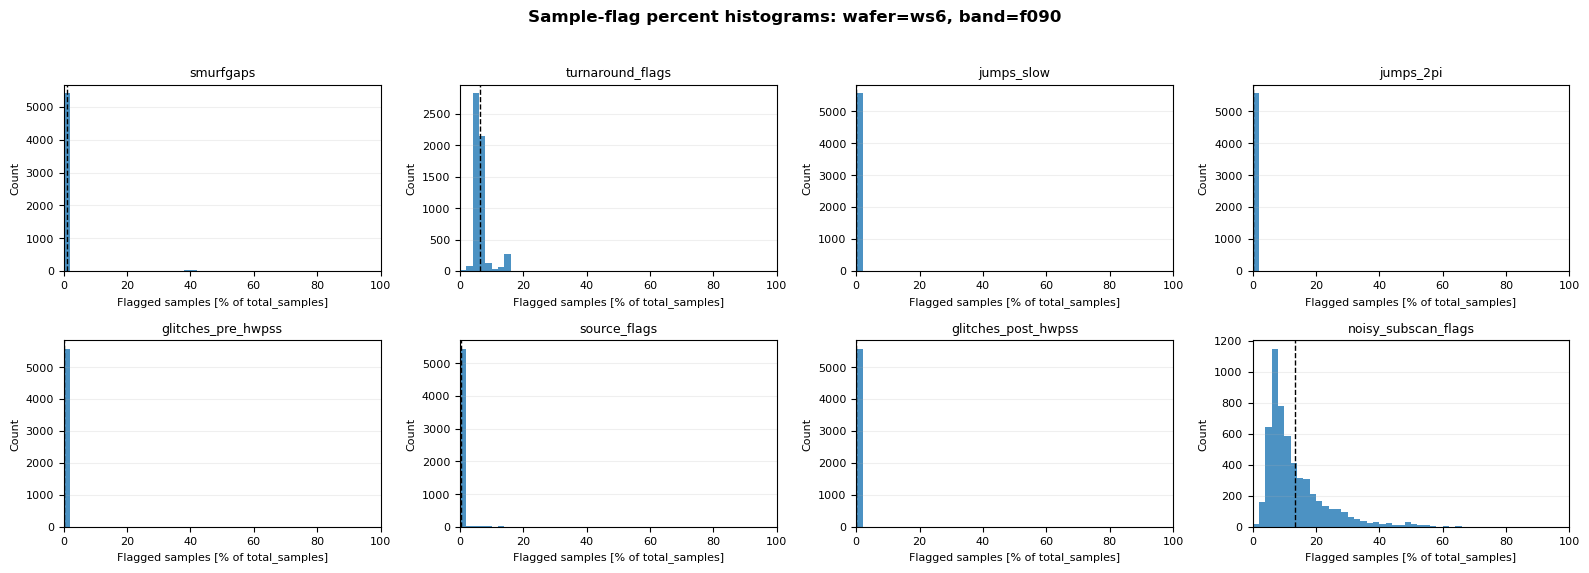

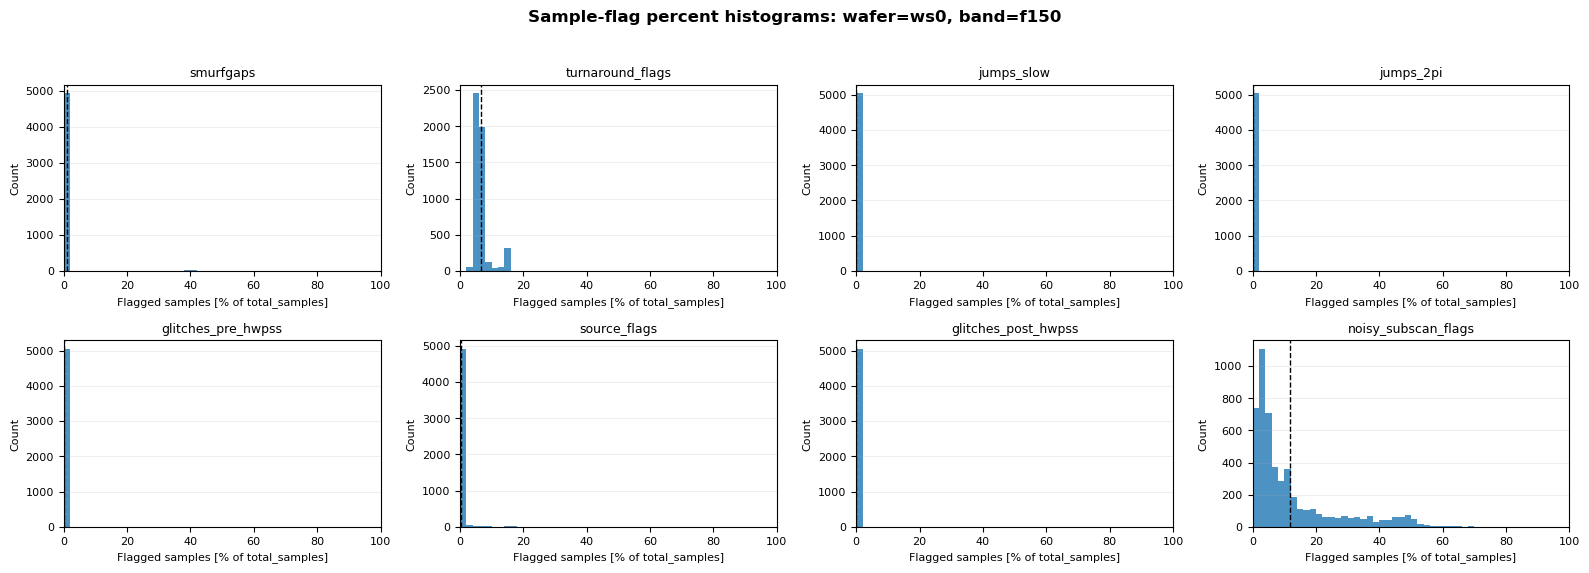

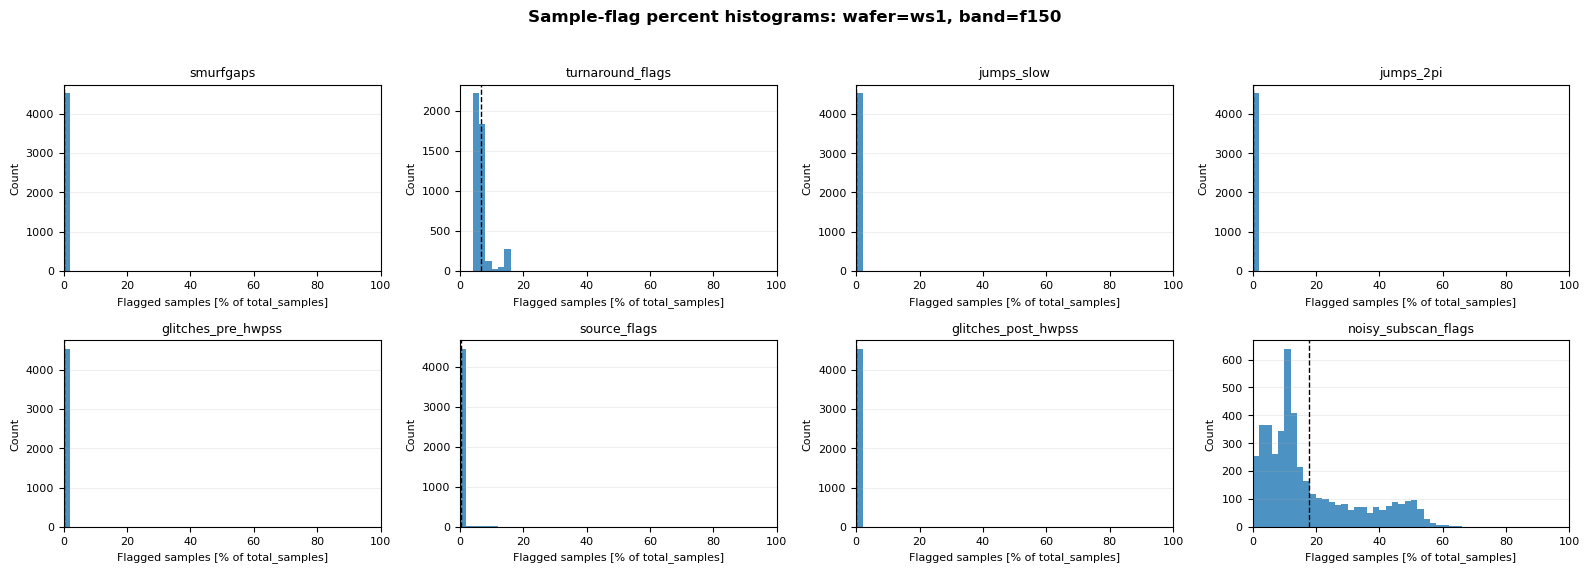

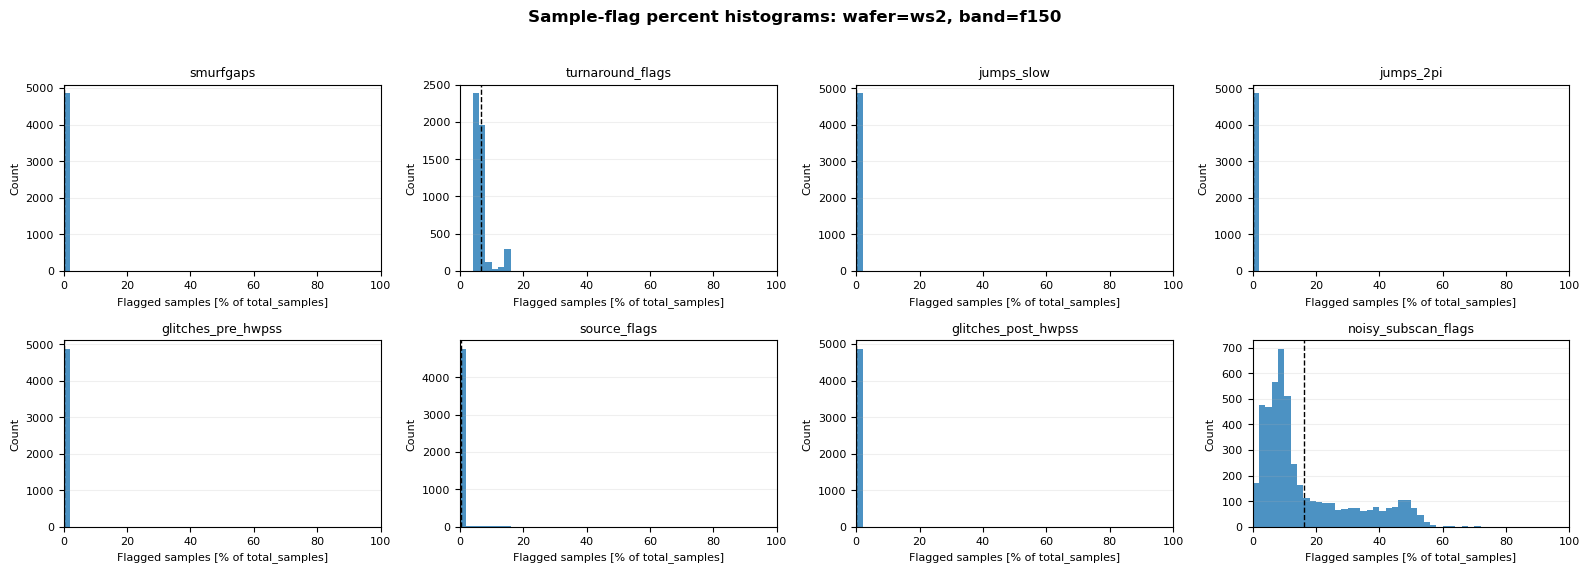

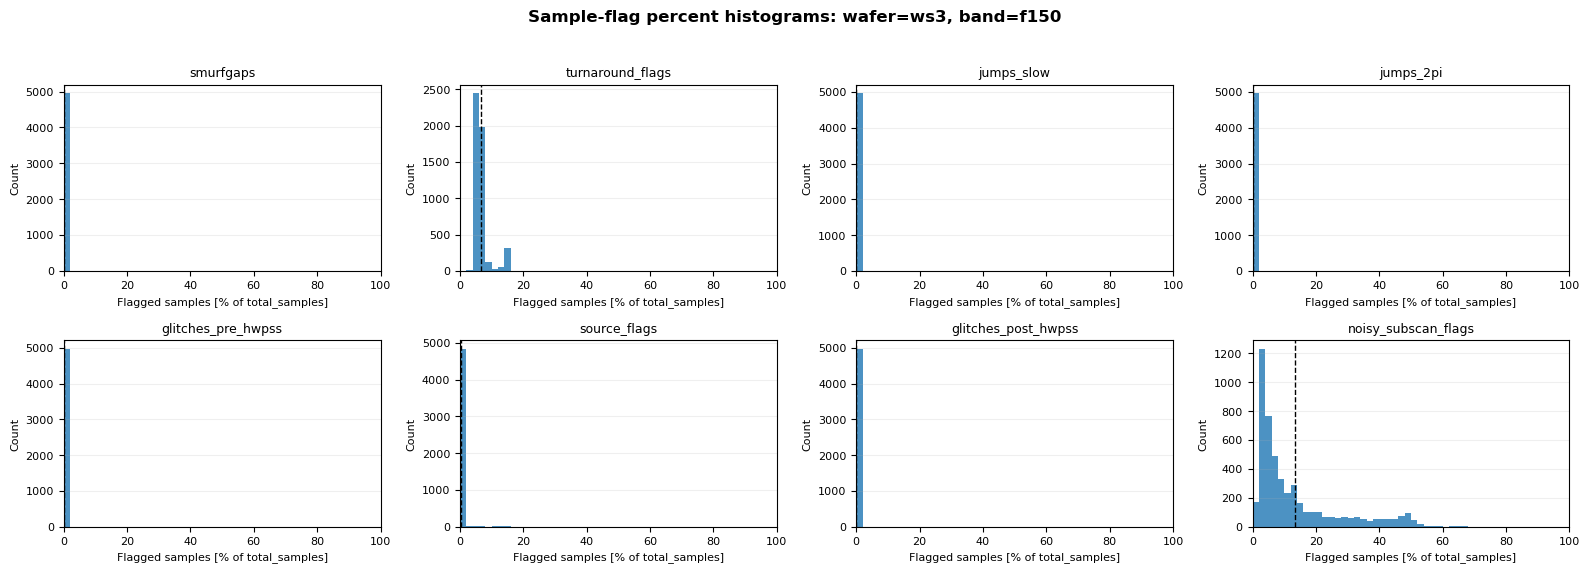

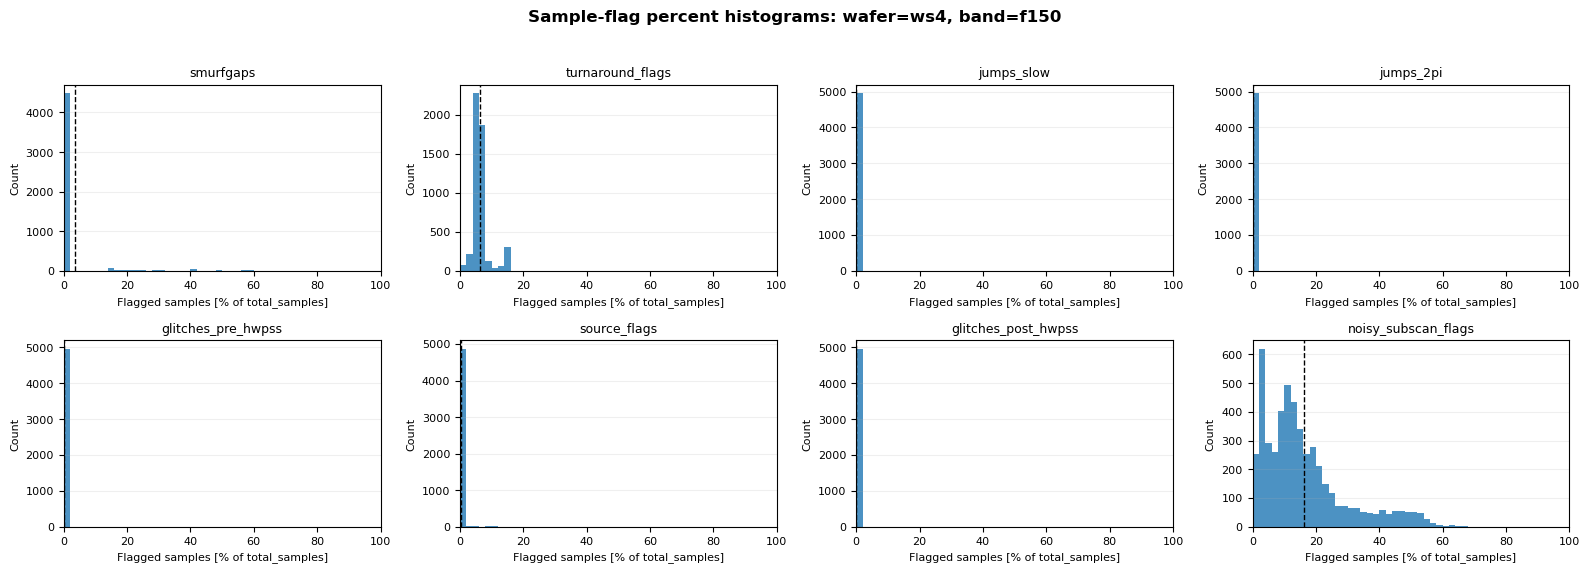

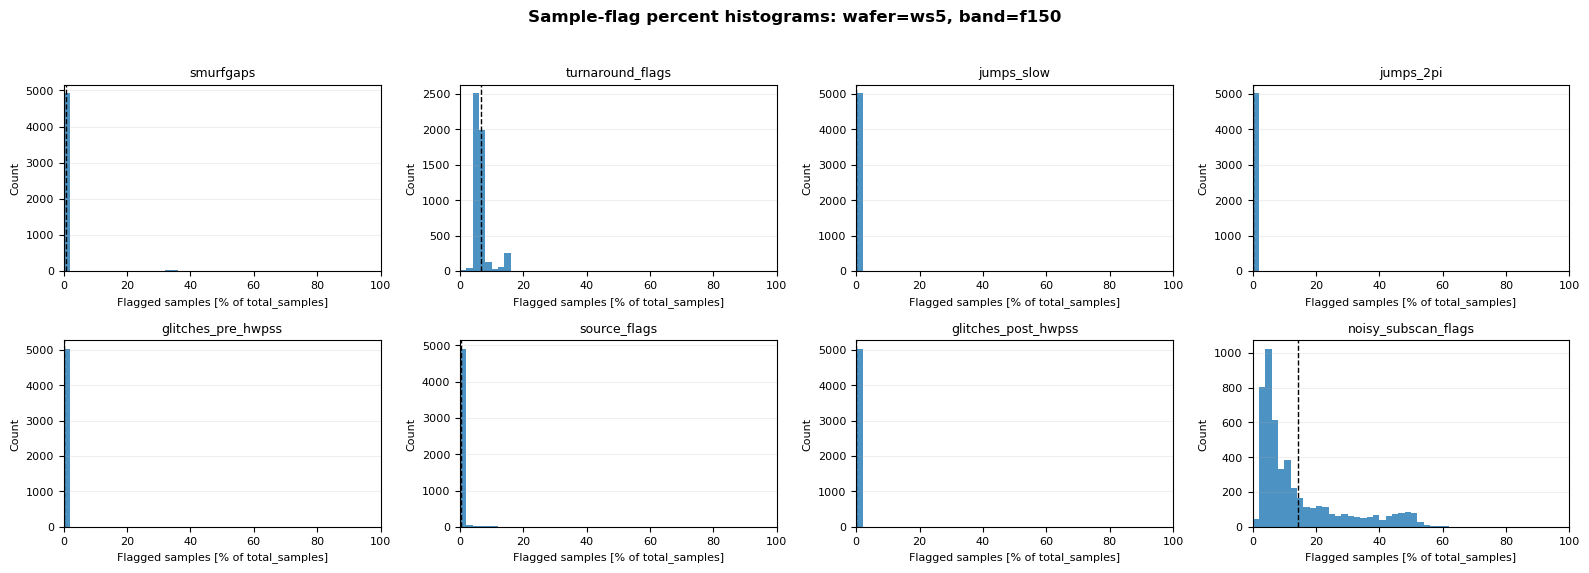

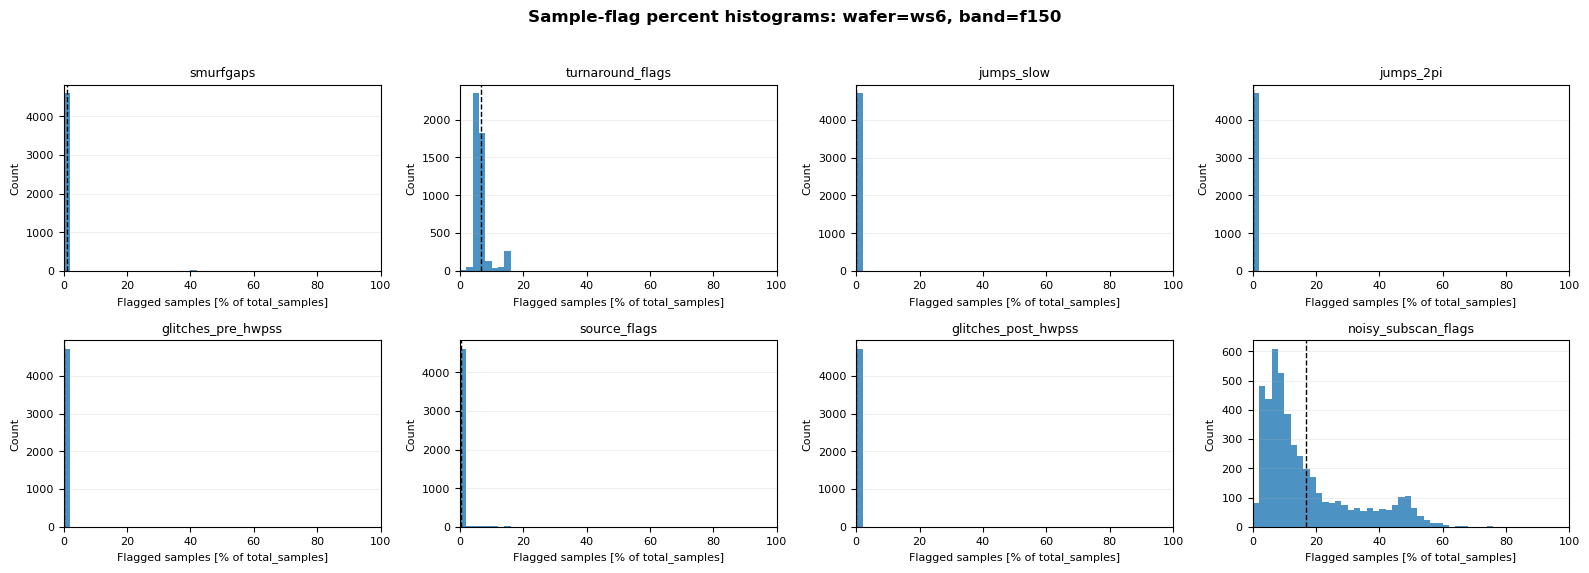

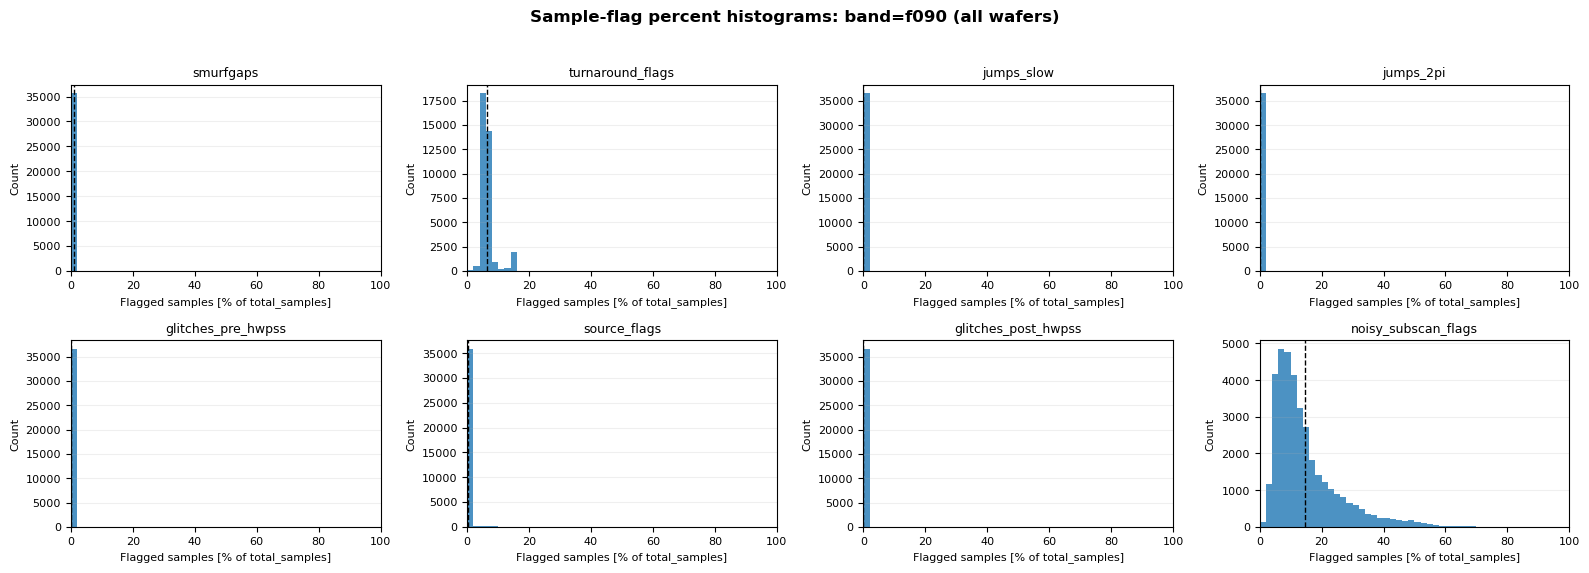

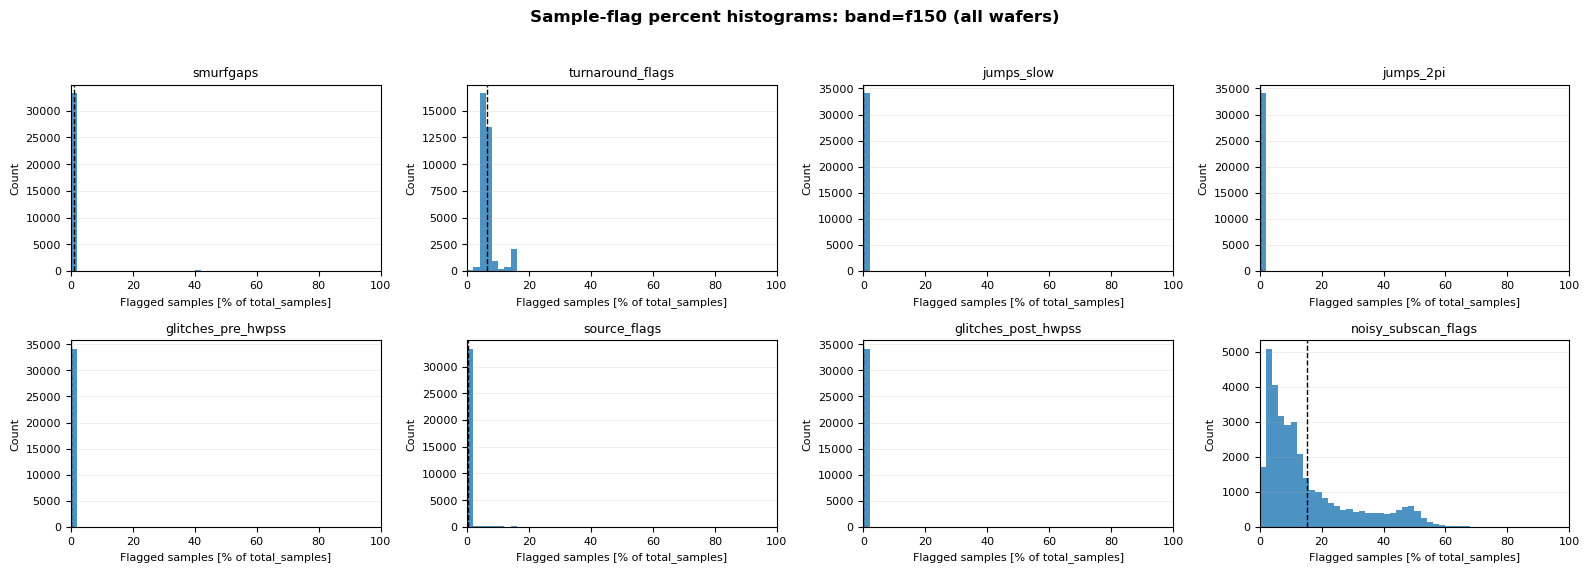

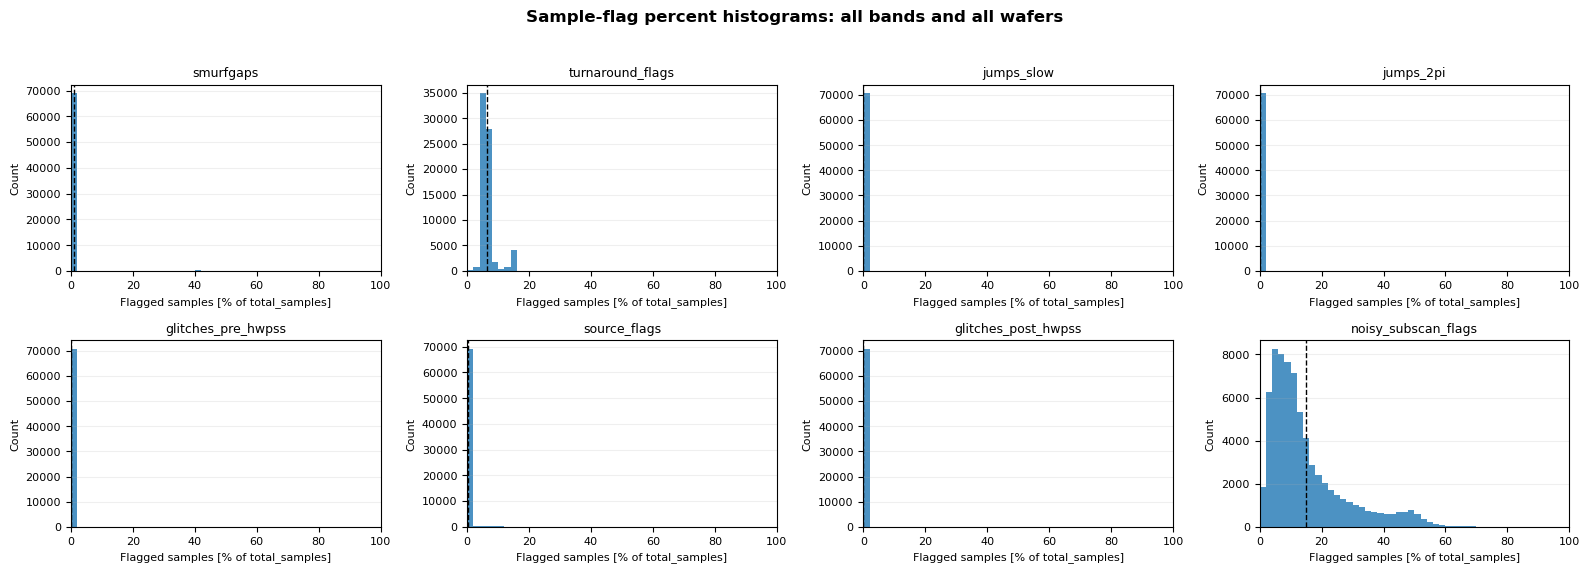

Saved summary CSVs and histogram figures.


In [7]:
from pathlib import Path
import sqlite3
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('default')

sqlite_path = Path('/scratch/gpfs/SIMONSOBS/sat-iso/v4/cuts_stats/satp1_20260417/databases/iso_v4_satp1_20260417.sqlite')
sample_flag_steps = [
    'smurfgaps',
    'turnaround_flags',
    'jumps_slow',
    'jumps_2pi',
    'glitches_pre_hwpss',
    'source_flags',
    'glitches_post_hwpss',
    'noisy_subscan_flags',
]

output_dir = sqlite_path.parent.parent / 'analysis' / 'sample_flag_percentages'
output_dir.mkdir(parents=True, exist_ok=True)

if not sqlite_path.exists():
    raise FileNotFoundError(f'SQLite file not found: {sqlite_path}')

with sqlite3.connect(sqlite_path) as conn:
    schema = pd.read_sql_query('PRAGMA table_info(obs)', conn)

obs_columns = set(schema['name'].tolist())
required = {'obs_id', 'wafer', 'band', 'total_samples'}
missing_required = sorted(required - obs_columns)
if missing_required:
    raise ValueError(f'Missing required columns in obs table: {missing_required}')

missing_steps = [c for c in sample_flag_steps if c not in obs_columns]
if missing_steps:
    raise ValueError(f'Missing expected sample-flag columns: {missing_steps}')

select_cols = ['obs_id', 'wafer', 'band', 'total_samples'] + sample_flag_steps
query = 'SELECT ' + ', '.join(select_cols) + ' FROM obs'
with sqlite3.connect(sqlite_path) as conn:
    df = pd.read_sql_query(query, conn)

df['wafer'] = df['wafer'].astype(str)
df['band'] = df['band'].astype(str)

for col in ['total_samples'] + sample_flag_steps:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0.0)

valid = df['total_samples'] > 0
df = df.loc[valid].copy()
if df.empty:
    raise ValueError('No rows with total_samples > 0 found in obs table.')

df['flagged_samples_sum'] = df[sample_flag_steps].sum(axis=1)
df['pct_all_flagged'] = 100.0 * np.clip(df['flagged_samples_sum'] / df['total_samples'], 0.0, 1.0)

for step in sample_flag_steps:
    pct_col = f'pct_{step}'
    frac = np.clip(df[step] / df['total_samples'], 0.0, 1.0)
    df[pct_col] = 100.0 * frac

pct_cols = [f'pct_{step}' for step in sample_flag_steps]
summary_metric_cols = ['pct_all_flagged'] + pct_cols

def weighted_percent_summary(sub_df: pd.DataFrame) -> dict[str, float]:
    total = float(sub_df['total_samples'].sum())
    if total <= 0:
        return {'pct_all_flagged': np.nan, **{f'pct_{s}': np.nan for s in sample_flag_steps}}
    out = {
        'pct_all_flagged': 100.0 * float(sub_df['flagged_samples_sum'].sum()) / total,
    }
    for step in sample_flag_steps:
        out[f'pct_{step}'] = 100.0 * float(sub_df[step].sum()) / total
    return out

# Weighted wafer-band summary: 100 * sum(step_counts) / sum(total_samples) within group
table_wafer_band = (
    df.groupby(['wafer', 'band'], dropna=False)
    .apply(lambda g: pd.Series(weighted_percent_summary(g)))
    .reset_index()
    .sort_values(['band', 'wafer'])
)

# Weighted band summary: 100 * sum(step_counts) / sum(total_samples) within group
table_band = (
    df.groupby(['band'], dropna=False)
    .apply(lambda g: pd.Series(weighted_percent_summary(g)))
    .reset_index()
    .sort_values('band')
)

# Weighted global summary using the same definition
table_global = pd.DataFrame([
    {'group': 'all_wafers_all_bands', **weighted_percent_summary(df)}
])

display_cols_wafer_band = ['wafer', 'band'] + summary_metric_cols
display_cols_band = ['band'] + summary_metric_cols
display_cols_global = ['group'] + summary_metric_cols

global_pct_all_flagged = float(table_global.loc[0, 'pct_all_flagged'])

print(f'Loaded rows with total_samples > 0: {len(df)}')
print(f'Output directory: {output_dir}')
print('Sample-flag columns:', sample_flag_steps)

print('\n0) Total flagged percent across all sample-cut steps:')
print(f"   sum(flagged_samples) / total_samples = {global_pct_all_flagged:.3f}%")

print('\n1) Weighted percent per step by wafer-band (total at left)')
display(table_wafer_band[display_cols_wafer_band])

print('\n2) Weighted percent per step by band (all wafers combined, total at left)')
display(table_band[display_cols_band])

print('\n3) Weighted percent per step for all bands and wafers combined (total at left)')
display(table_global[display_cols_global])

table_wafer_band.to_csv(output_dir / 'sample_flag_percent_summary_by_wafer_band.csv', index=False)
table_band.to_csv(output_dir / 'sample_flag_percent_summary_by_band.csv', index=False)
table_global.to_csv(output_dir / 'sample_flag_percent_summary_global.csv', index=False)

def plot_hist_grid(sub_df, title, save_path):
    n_steps = len(sample_flag_steps)
    n_cols = min(4, n_steps)
    n_rows = int(math.ceil(n_steps / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.0 * n_cols, 2.9 * n_rows), squeeze=False)

    for i, step in enumerate(sample_flag_steps):
        r, c = divmod(i, n_cols)
        ax = axes[r][c]
        values = sub_df[f'pct_{step}'].to_numpy()
        values = values[np.isfinite(values)]
        if values.size == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
        else:
            ax.hist(values, bins=50, range=(0, 100), alpha=0.8, edgecolor='none')
            ax.axvline(np.mean(values), color='k', linestyle='--', linewidth=1)
        ax.set_xlim(0, 100)
        ax.set_title(step, fontsize=9)
        ax.set_xlabel('Flagged samples [% of total_samples]', fontsize=8)
        ax.set_ylabel('Count', fontsize=8)
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.2, axis='y')

    total_axes = n_rows * n_cols
    for j in range(n_steps, total_axes):
        r, c = divmod(j, n_cols)
        axes[r][c].set_visible(False)

    fig.suptitle(title, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# 4) One figure per wafer-band, one subplot per step
wafer_band_groups = sorted(df.groupby(['wafer', 'band']).groups.keys(), key=lambda x: (x[1], x[0]))
for wafer, band in wafer_band_groups:
    sub = df[(df['wafer'] == wafer) & (df['band'] == band)]
    title = f'Sample-flag percent histograms: wafer={wafer}, band={band}'
    save_path = output_dir / f'sample_flag_hists_percent_wafer_{wafer}_band_{band}.png'
    plot_hist_grid(sub, title, save_path)

# 5) One figure per band including all wafers
band_values = sorted(df['band'].dropna().unique())
for band in band_values:
    sub = df[df['band'] == band]
    title = f'Sample-flag percent histograms: band={band} (all wafers)'
    save_path = output_dir / f'sample_flag_hists_percent_band_{band}.png'
    plot_hist_grid(sub, title, save_path)

# 6) One figure for both bands and all wafers
plot_hist_grid(
    df,
    'Sample-flag percent histograms: all bands and all wafers',
    output_dir / 'sample_flag_hists_percent_all_wafers_all_bands.png',
)

print('Saved summary CSVs and histogram figures.')

In [8]:
# --- Noise statistics summary and plots: white noise, fknee, alpha (T, Q, U) ---

# Define noise metric columns for each pol (q50 metrics; array removed)
noise_metrics = [
    ('white_noise_q50', 'White Noise q50 [pipeline units]'),
    ('fknee_q50', 'Knee Frequency q50 [Hz]'),
    ('alpha_q50', 'Alpha q50 [dimensionless]'),
]
pols = ['T', 'Q', 'U']

# Build a DataFrame with only the noise columns needed for this analysis.
noise_cols = [f'noise_{pol}_{metric}' for pol in pols for metric, _ in noise_metrics]
noise_labels = {f'noise_{pol}_{metric}': f'{pol} {label}' for pol in pols for metric, label in noise_metrics}
noise_select_cols = ['wafer', 'band', 'total_samples'] + noise_cols

with sqlite3.connect(sqlite_path) as conn:
    df_noise = pd.read_sql_query(
        'SELECT ' + ', '.join(noise_select_cols) + ' FROM obs',
        conn,
    )

df_noise['wafer'] = df_noise['wafer'].astype(str)
df_noise['band'] = df_noise['band'].astype(str)
for col in ['total_samples'] + noise_cols:
    df_noise[col] = pd.to_numeric(df_noise[col], errors='coerce')

valid_noise = (df_noise['total_samples'] > 0) & df_noise[noise_cols].notna().any(axis=1)
df_noise = df_noise.loc[valid_noise].copy()

def weighted_noise_summary(sub_df: pd.DataFrame) -> dict:
    out = {}
    for col in noise_cols:
        vals = sub_df[col].to_numpy()
        weights = sub_df['total_samples'].to_numpy()
        mask = np.isfinite(vals) & (weights > 0)
        out[col] = np.average(vals[mask], weights=weights[mask]) if np.any(mask) else np.nan
    return out

noise_table_wafer_band = (
    df_noise.groupby(['wafer', 'band'], dropna=False)
    .apply(lambda g: pd.Series(weighted_noise_summary(g)))
    .reset_index()
    .sort_values(['band', 'wafer'])
)
noise_table_band = (
    df_noise.groupby(['band'], dropna=False)
    .apply(lambda g: pd.Series(weighted_noise_summary(g)))
    .reset_index()
    .sort_values('band')
)
noise_table_global = pd.DataFrame([
    {'group': 'all_wafers_all_bands', **weighted_noise_summary(df_noise)}
])

noise_display_cols = ['wafer', 'band'] + noise_cols
noise_display_cols_band = ['band'] + noise_cols
noise_display_cols_global = ['group'] + noise_cols

print('\nNoise statistics (array removed): weighted mean by wafer-band')
display(noise_table_wafer_band[noise_display_cols].rename(columns=noise_labels))
print('\nNoise statistics (array removed): weighted mean by band')
display(noise_table_band[noise_display_cols_band].rename(columns=noise_labels))
print('\nNoise statistics (array removed): weighted mean, all wafers and bands')
display(noise_table_global[noise_display_cols_global].rename(columns=noise_labels))

noise_table_wafer_band.rename(columns=noise_labels).to_csv(output_dir / 'noise_stats_weighted_by_wafer_band.csv', index=False)
noise_table_band.rename(columns=noise_labels).to_csv(output_dir / 'noise_stats_weighted_by_band.csv', index=False)
noise_table_global.rename(columns=noise_labels).to_csv(output_dir / 'noise_stats_weighted_global.csv', index=False)
print('Saved noise summary tables (array removed).')



Noise statistics (array removed): weighted mean by wafer-band


/tmp/ipykernel_341776/3138446516.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series(weighted_noise_summary(g)))
/tmp/ipykernel_341776/3138446516.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series(weighted_noise_summary(g)))


,wafer,band,T White Noise q50 [pipeline units],T Knee Frequency q50 [Hz],T Alpha q50 [dimensionless],Q White Noise q50 [pipeline units],Q Knee Frequency q50 [Hz],Q Alpha q50 [dimensionless],U White Noise q50 [pipeline units],U Knee Frequency q50 [Hz],U Alpha q50 [dimensionless]
0,ws0,f090,0.000027,1.176140,3.131000,0.000499,0.001957,2.782253,0.000499,0.001995,2.774766
2,ws1,f090,0.000031,1.358799,3.001591,0.000569,0.005090,2.260797,0.000569,0.005082,2.239674
4,ws2,f090,0.000032,1.319244,3.519721,0.000577,0.005603,2.183029,0.000577,0.005890,2.137397
6,ws3,f090,0.000030,1.726393,2.525003,0.000479,0.006088,2.165180,0.000479,0.006253,2.139935
8,ws4,f090,0.000027,1.525919,2.675650,0.000567,0.005095,2.284160,0.000567,0.005153,2.314916
10,ws5,f090,0.000032,1.169967,2.688288,0.000919,0.005323,2.322416,0.000920,0.005301,2.333840
12,ws6,f090,0.000030,1.398025,2.605945,0.000551,0.004625,2.294746,0.000551,0.004827,2.264810
1,ws0,f150,0.000041,1.884808,3.510941,0.000611,0.001697,2.872164,0.000611,0.001699,2.874635
3,ws1,f150,0.000044,1.875298,3.767823,0.000657,0.004917,2.345232,0.000657,0.004915,2.339633
5,ws2,f150,0.000045,1.817783,3.743608,0.000684,0.005808,2.215489,0.000684,0.005867,2.202809



Noise statistics (array removed): weighted mean by band


,band,T White Noise q50 [pipeline units],T Knee Frequency q50 [Hz],T Alpha q50 [dimensionless],Q White Noise q50 [pipeline units],Q Knee Frequency q50 [Hz],Q Alpha q50 [dimensionless],U White Noise q50 [pipeline units],U Knee Frequency q50 [Hz],U Alpha q50 [dimensionless]
0,f090,0.000030,1.356015,2.915950,0.000574,0.004457,2.379855,0.000574,0.004565,2.364803
1,f150,0.000044,1.906402,3.515322,0.000689,0.004752,2.381455,0.000689,0.004705,2.387963



Noise statistics (array removed): weighted mean, all wafers and bands


,group,T White Noise q50 [pipeline units],T Knee Frequency q50 [Hz],T Alpha q50 [dimensionless],Q White Noise q50 [pipeline units],Q Knee Frequency q50 [Hz],Q Alpha q50 [dimensionless],U White Noise q50 [pipeline units],U Knee Frequency q50 [Hz],U Alpha q50 [dimensionless]
0,all_wafers_all_bands,0.000038,1.70226,3.29301,0.000646,0.004643,2.380862,0.000646,0.004653,2.379373


Saved noise summary tables (array removed).


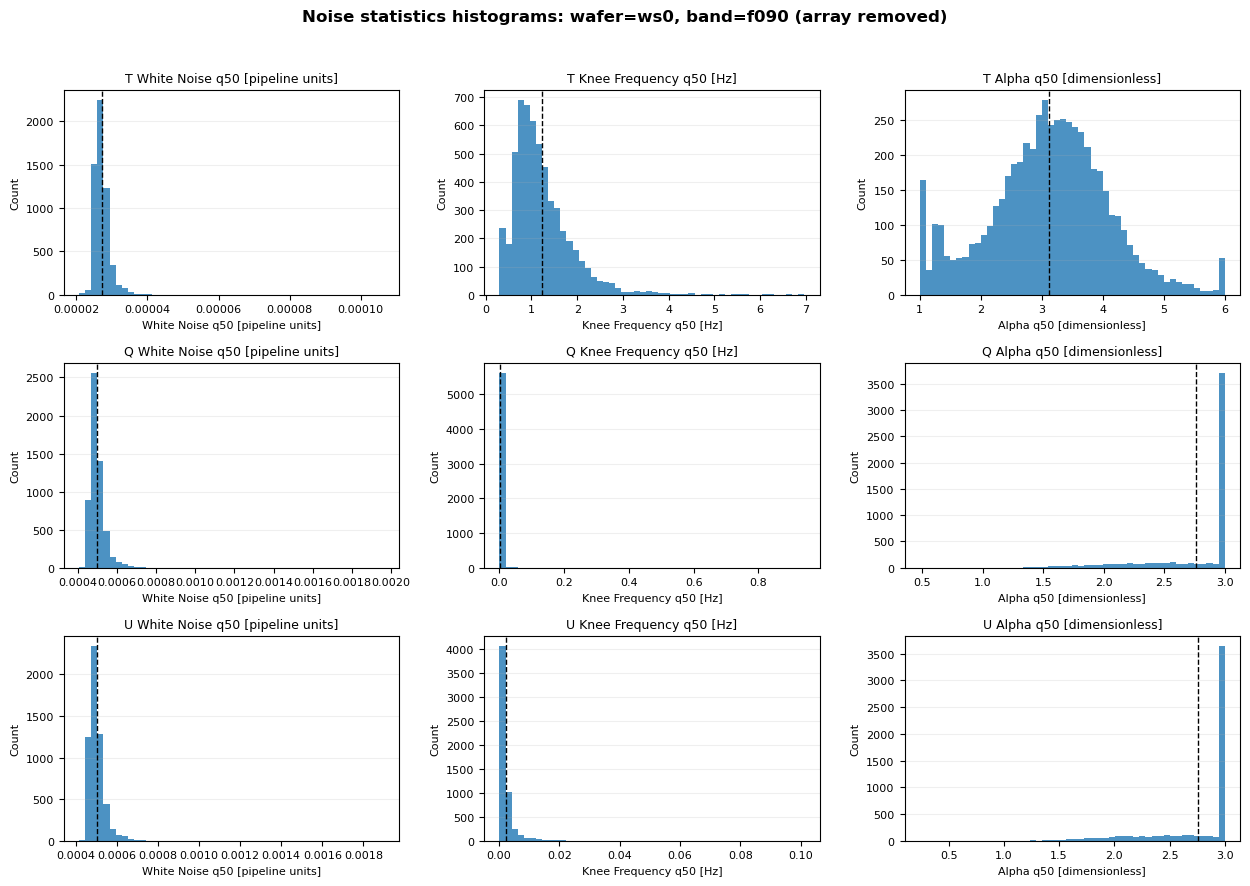

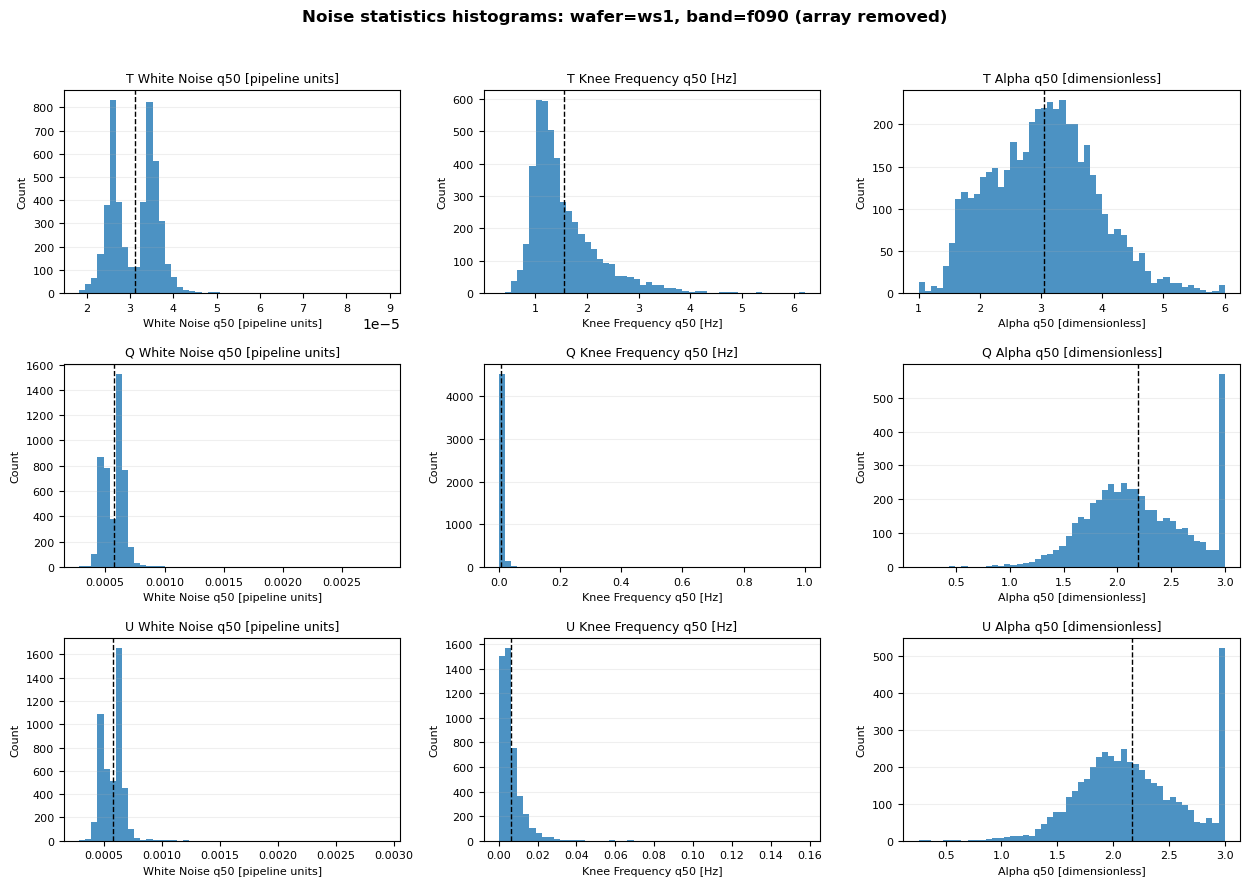

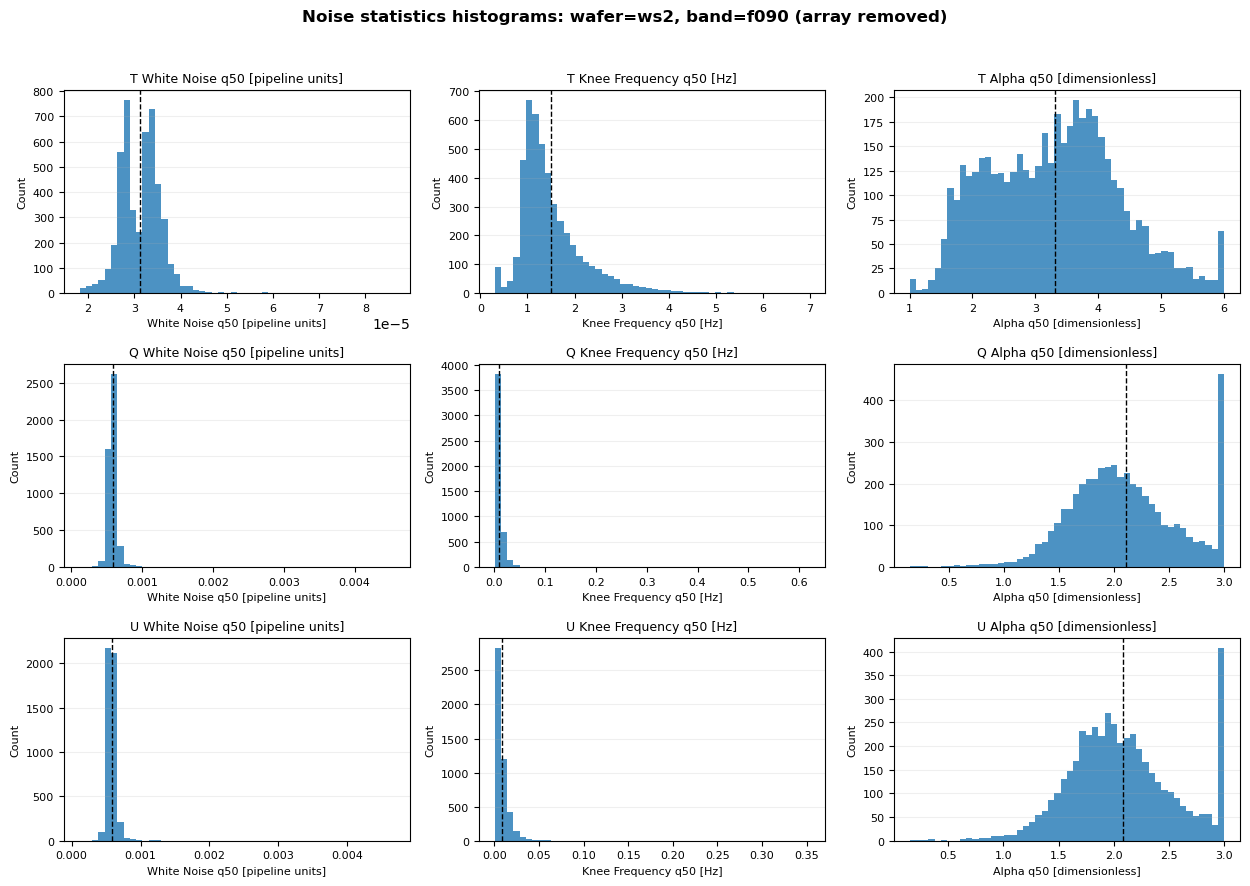

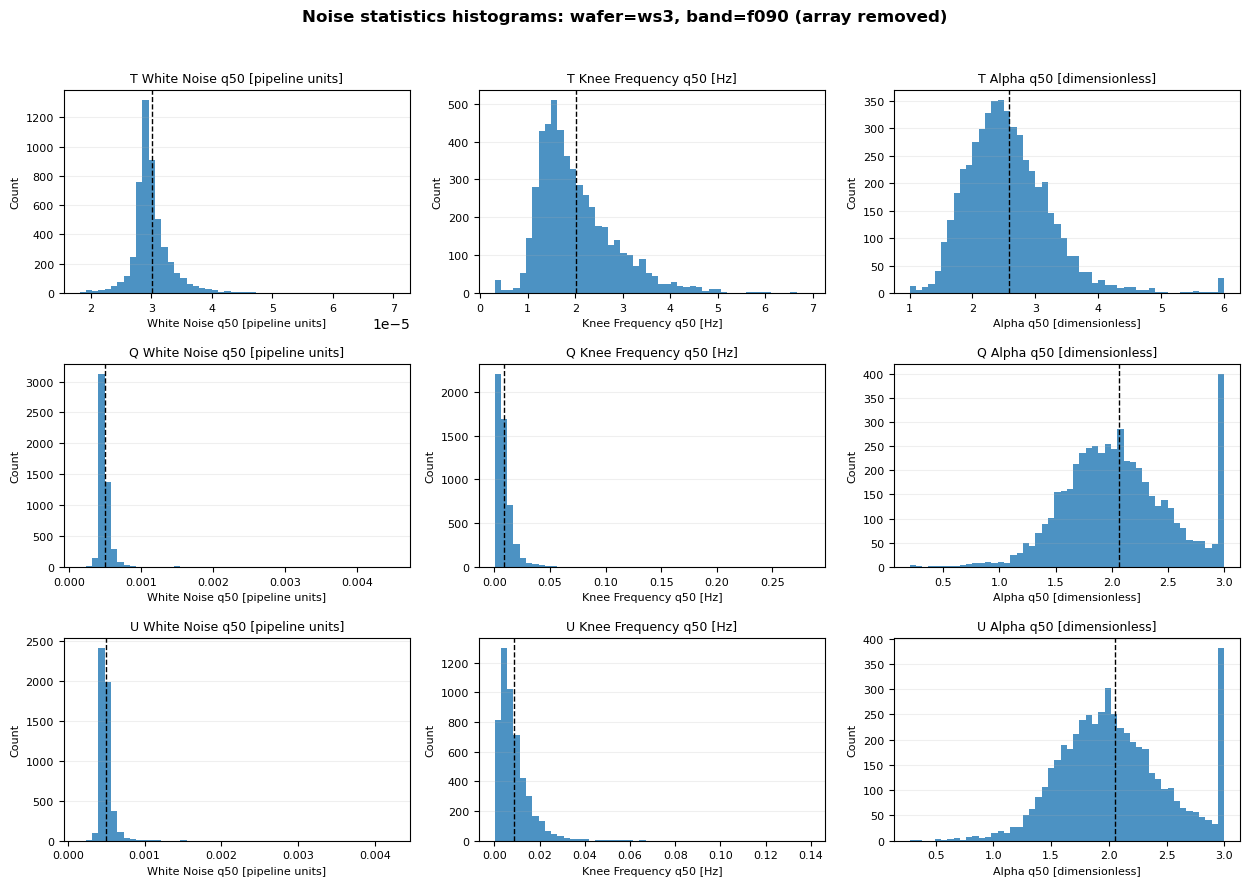

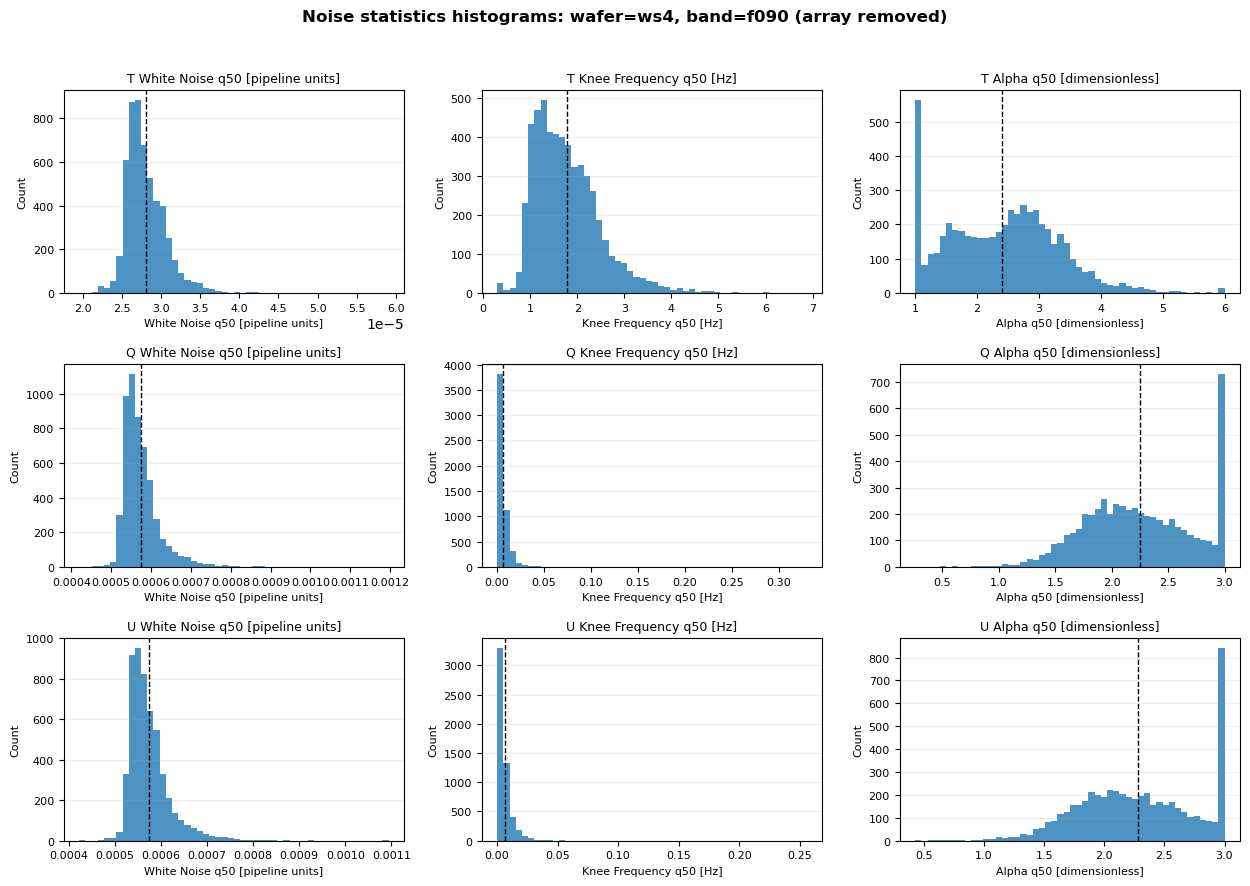

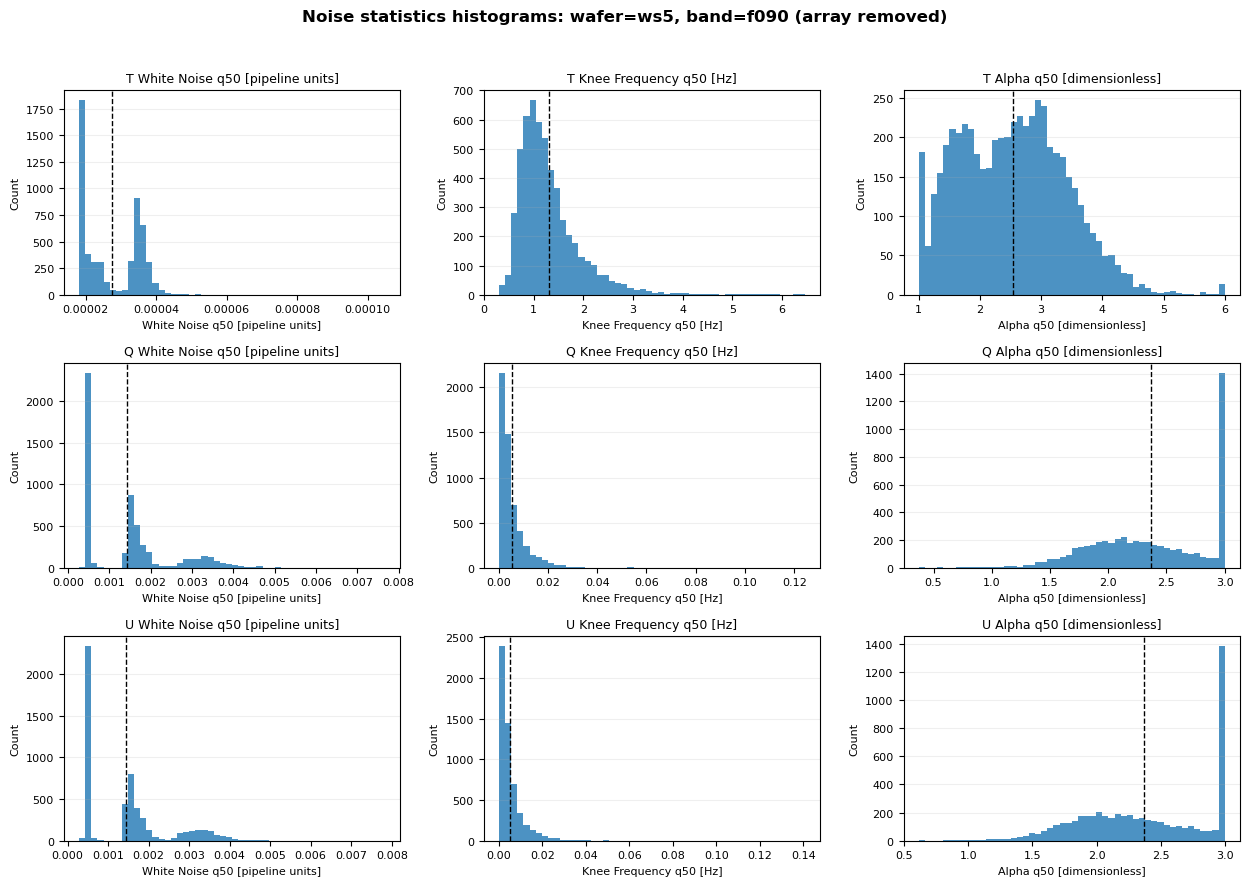

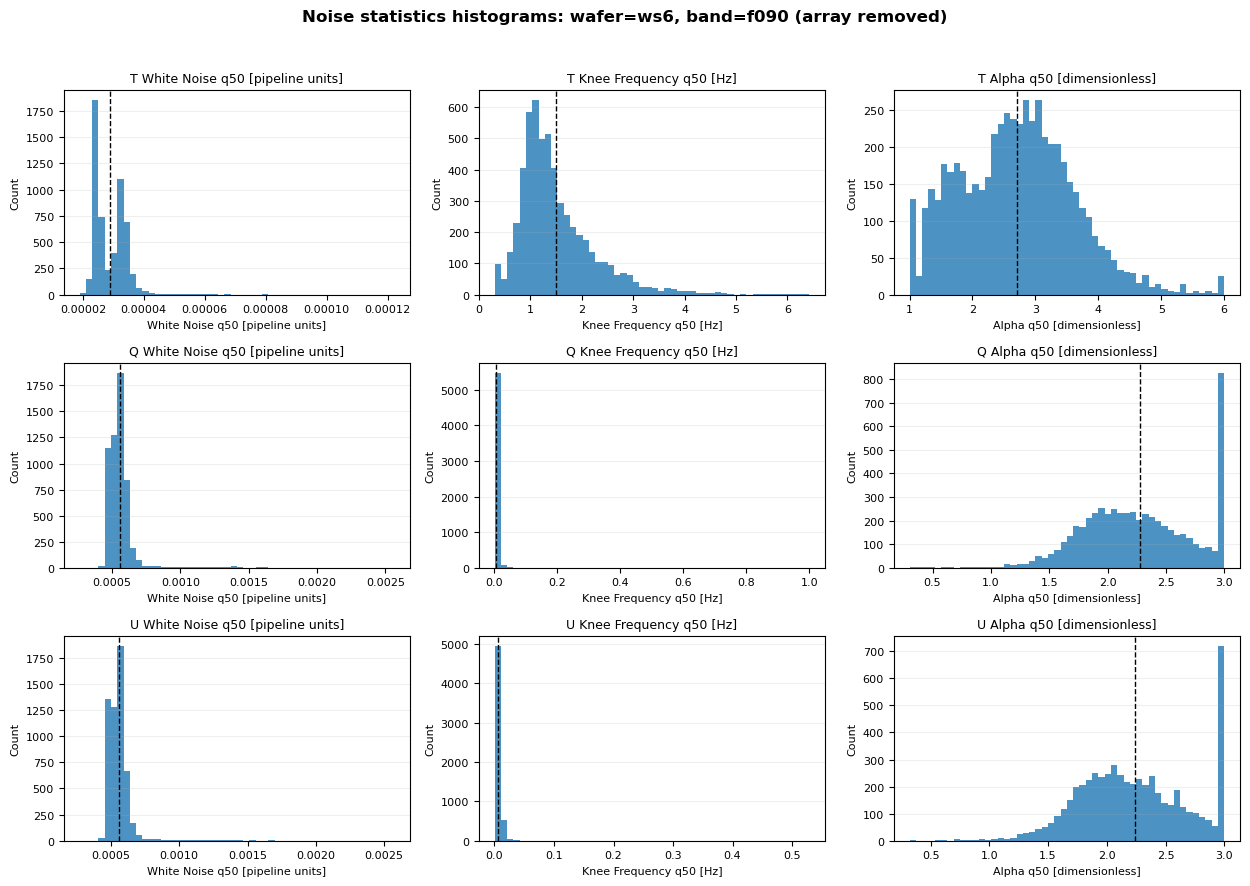

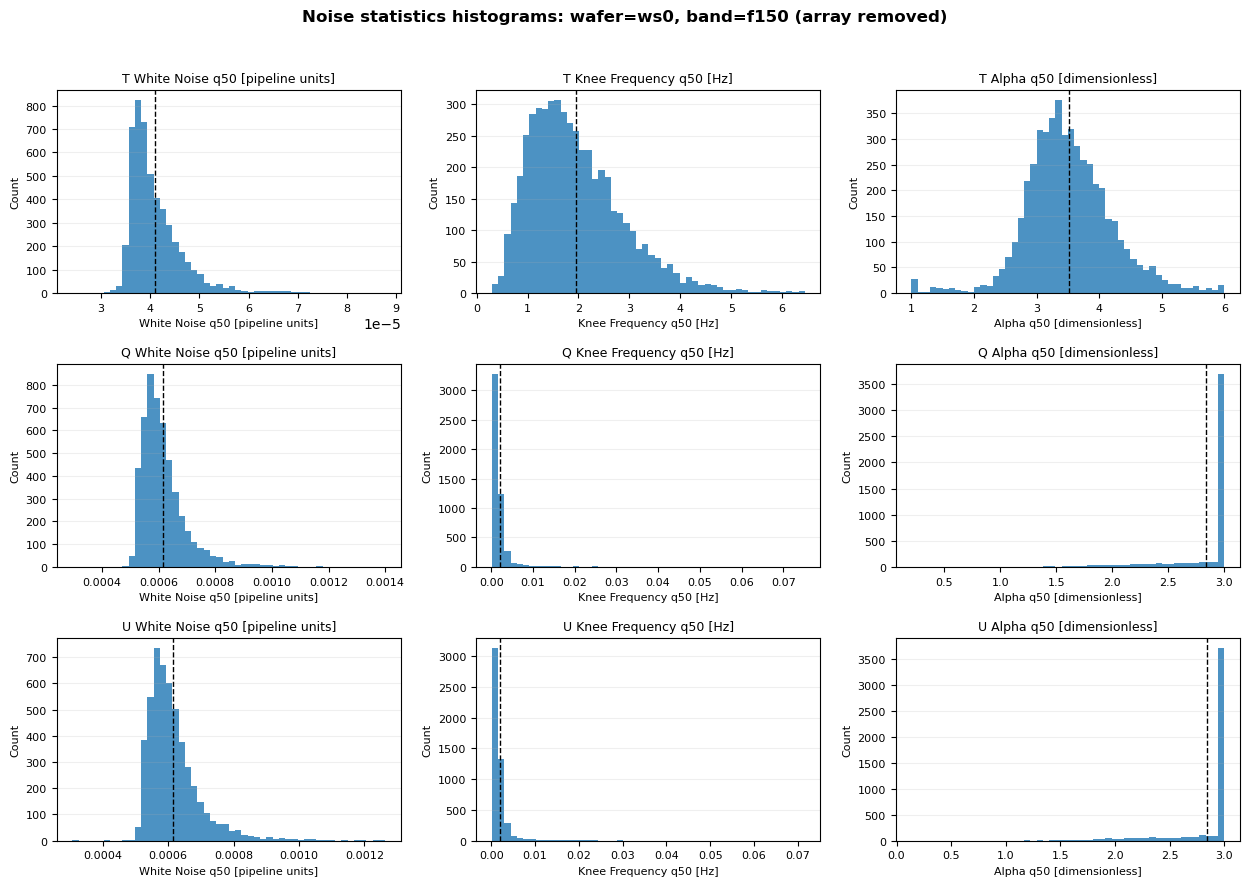

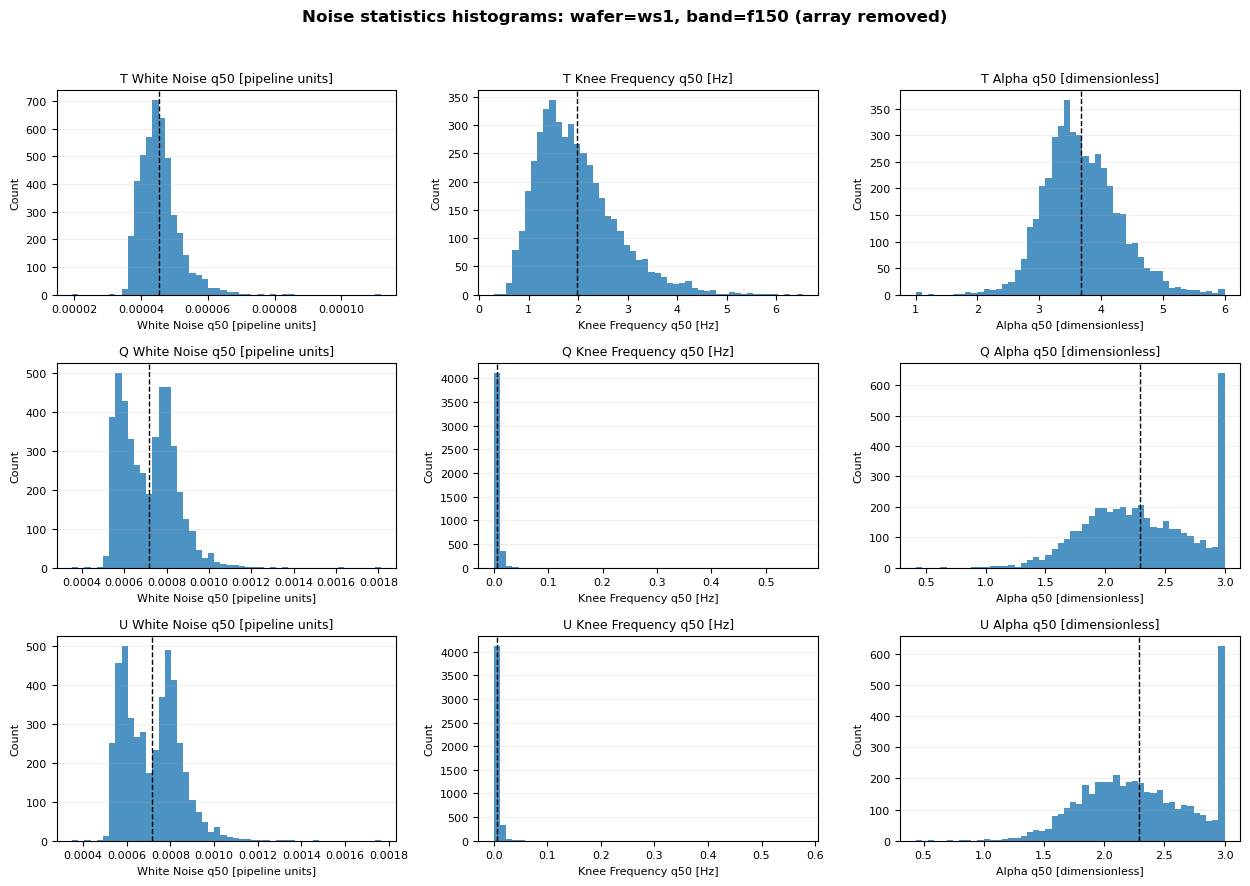

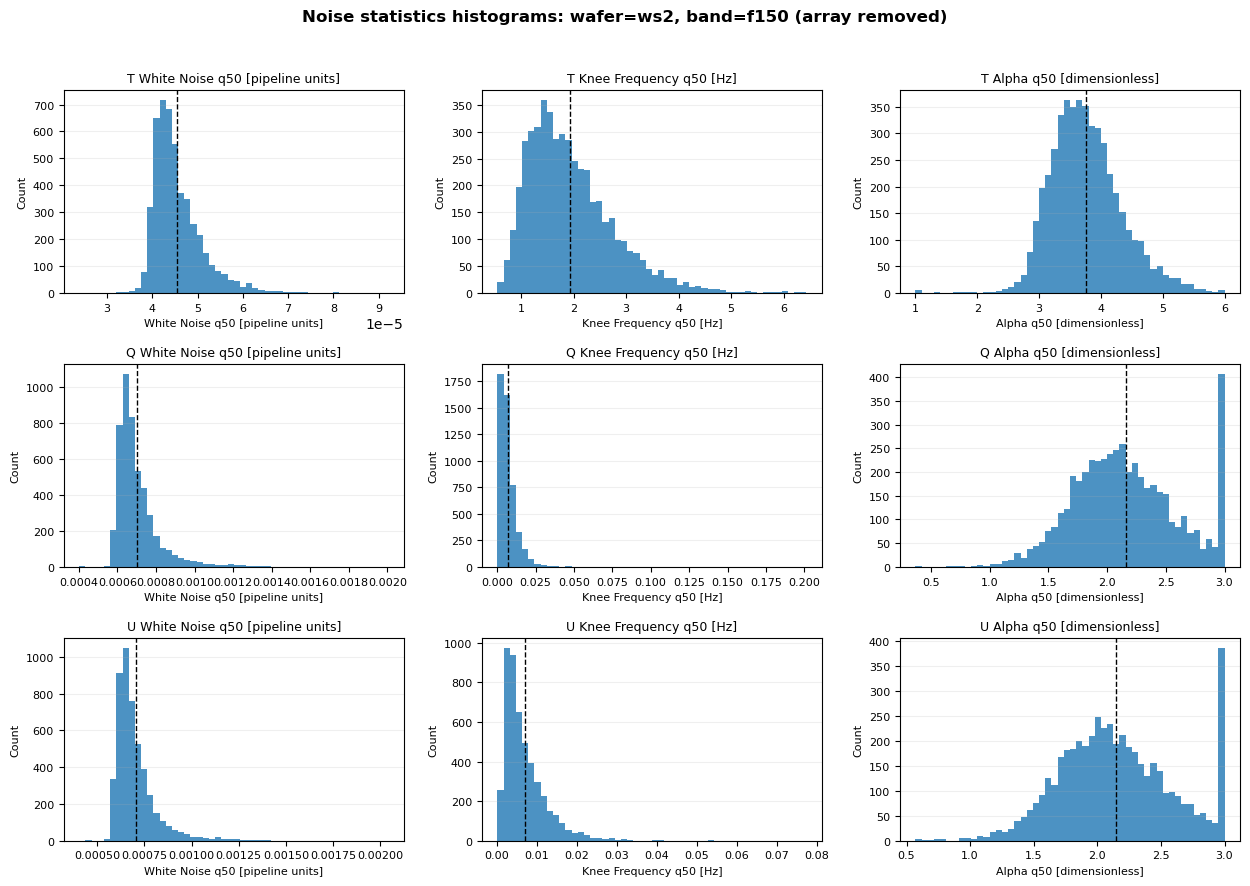

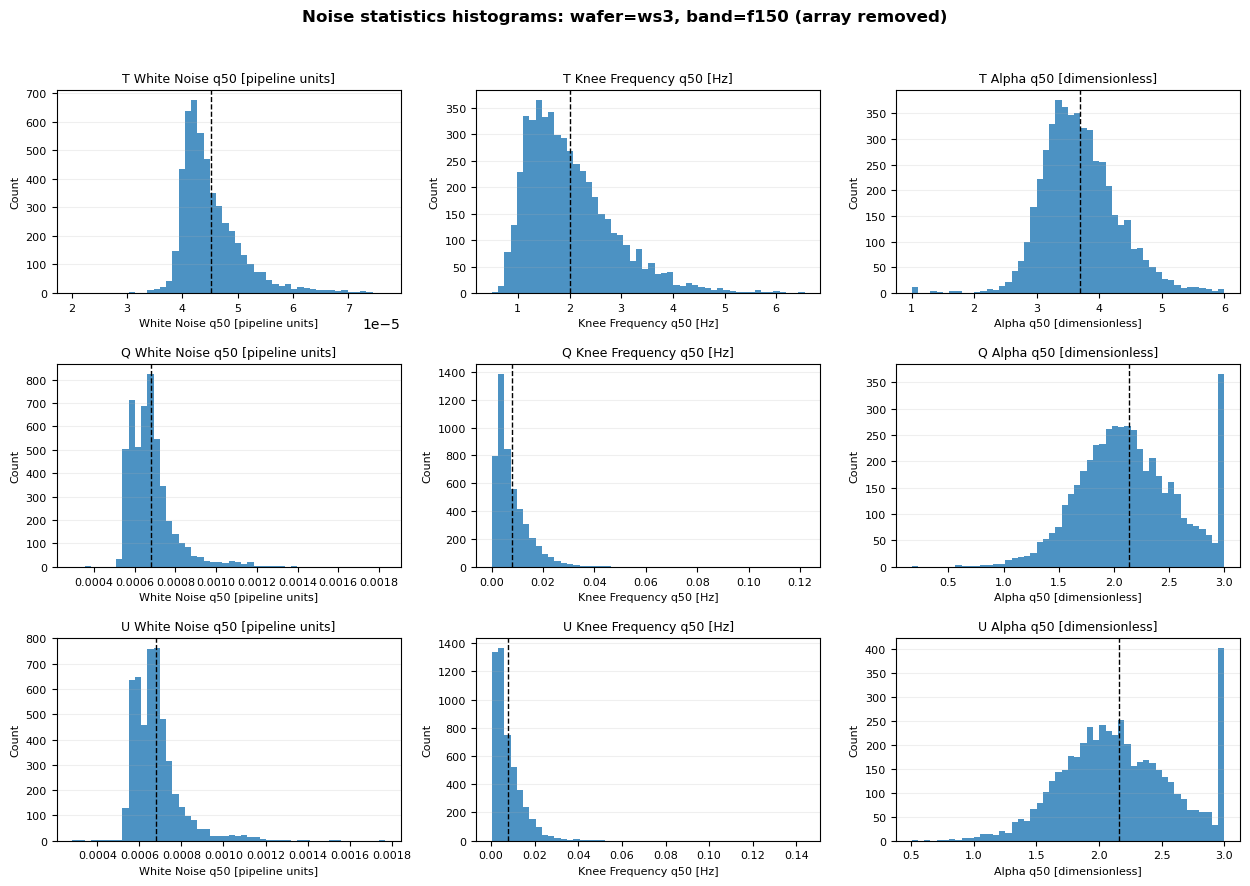

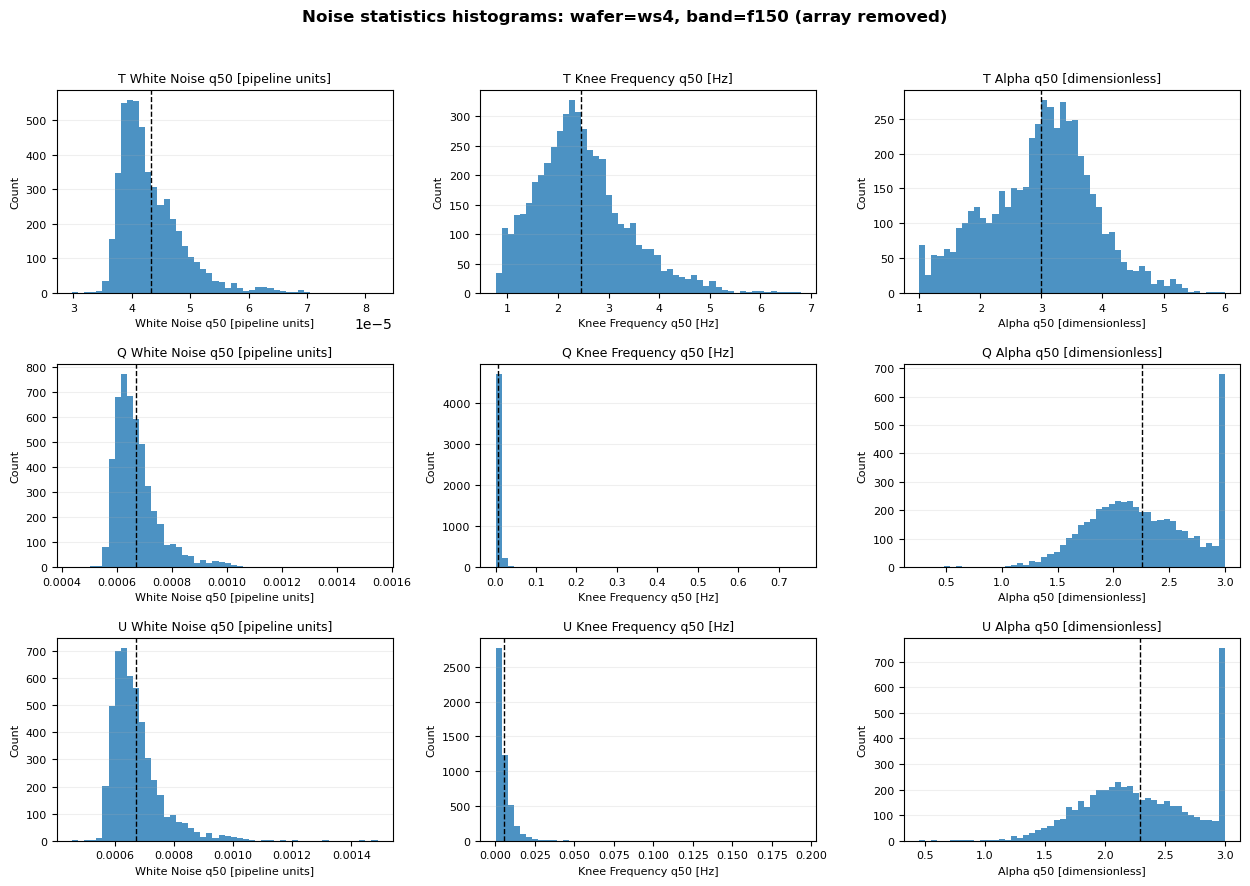

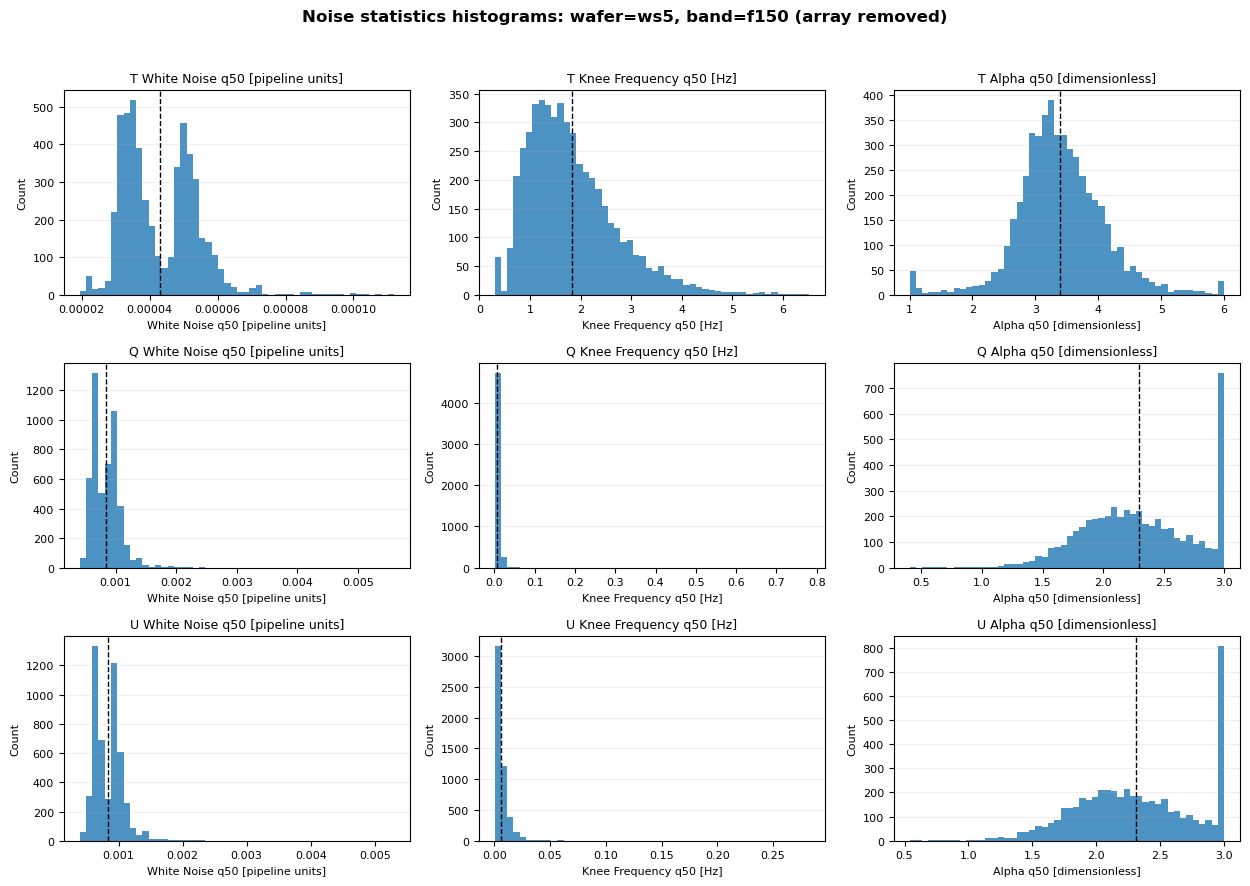

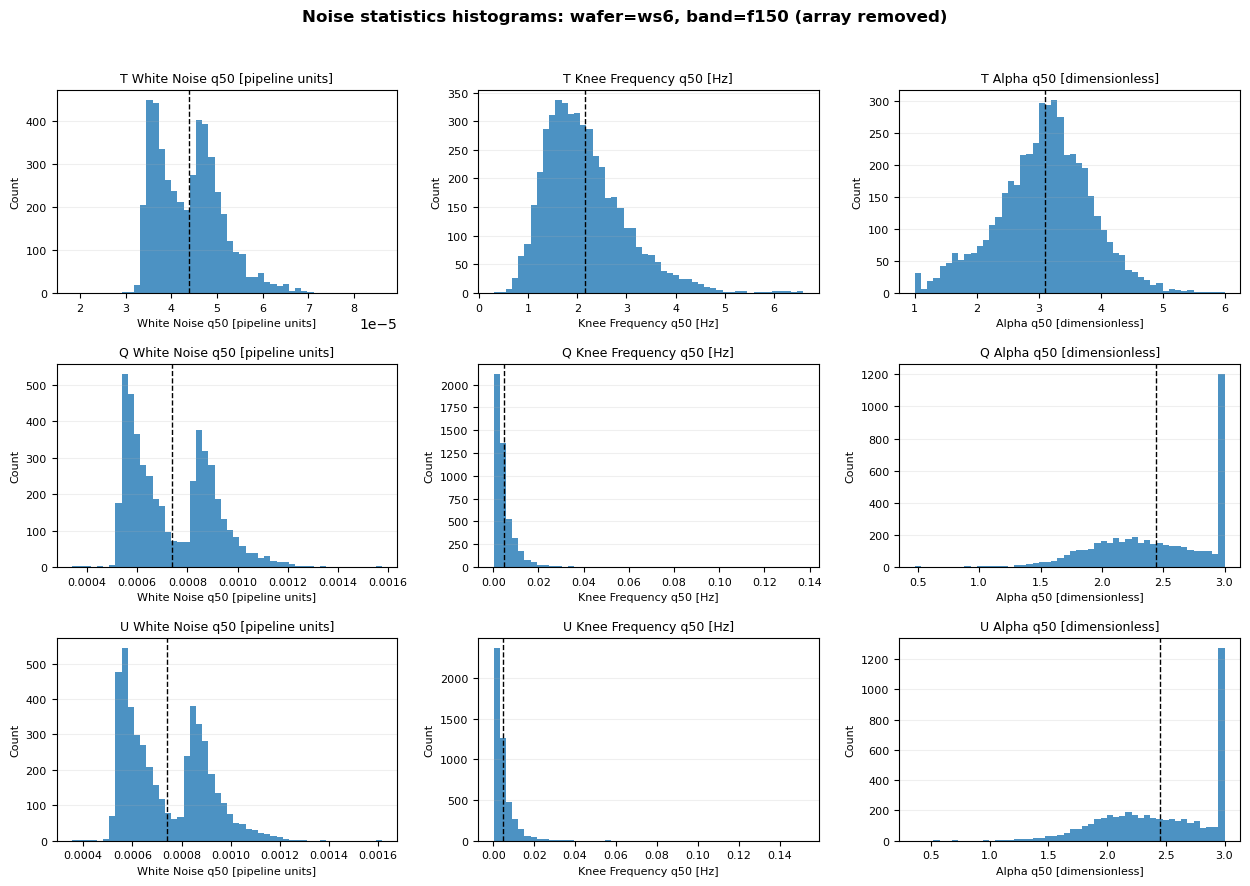

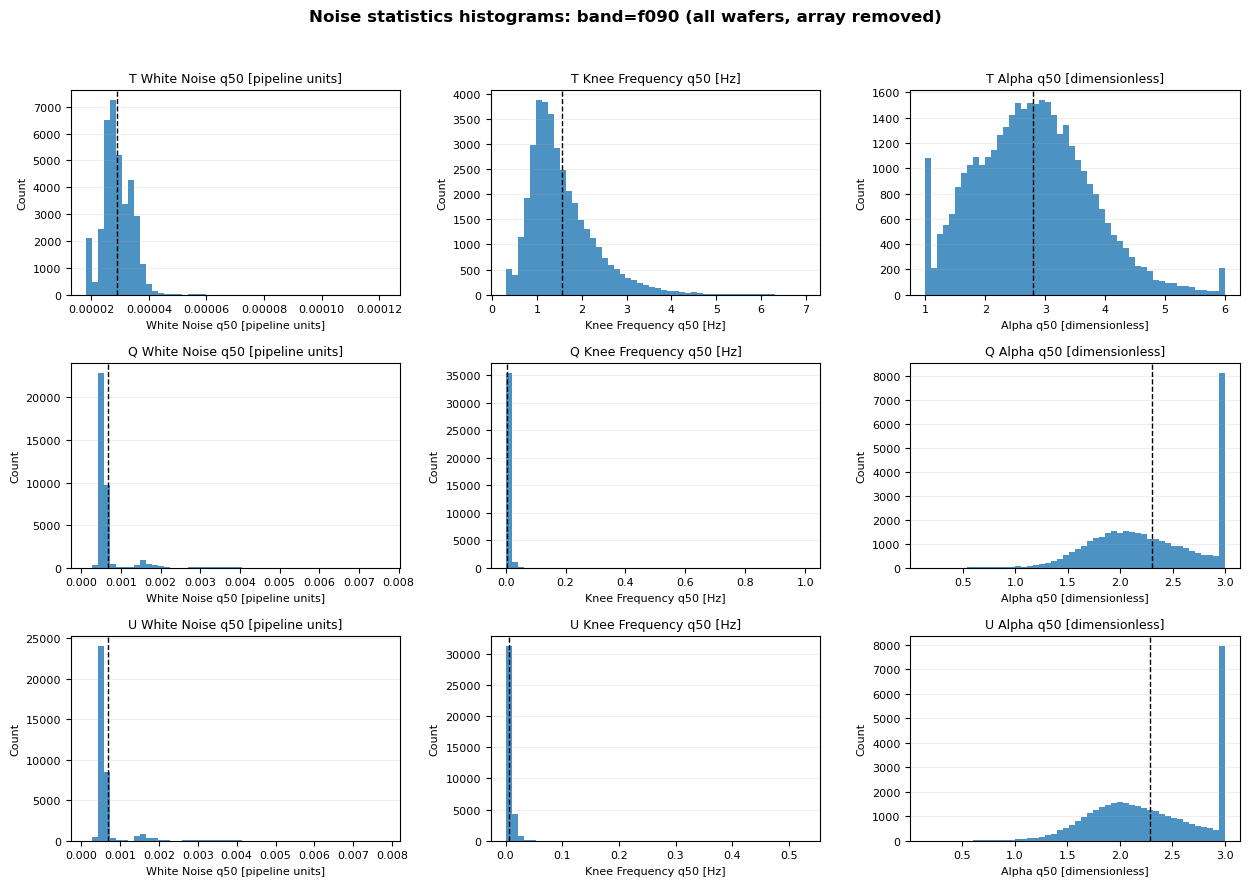

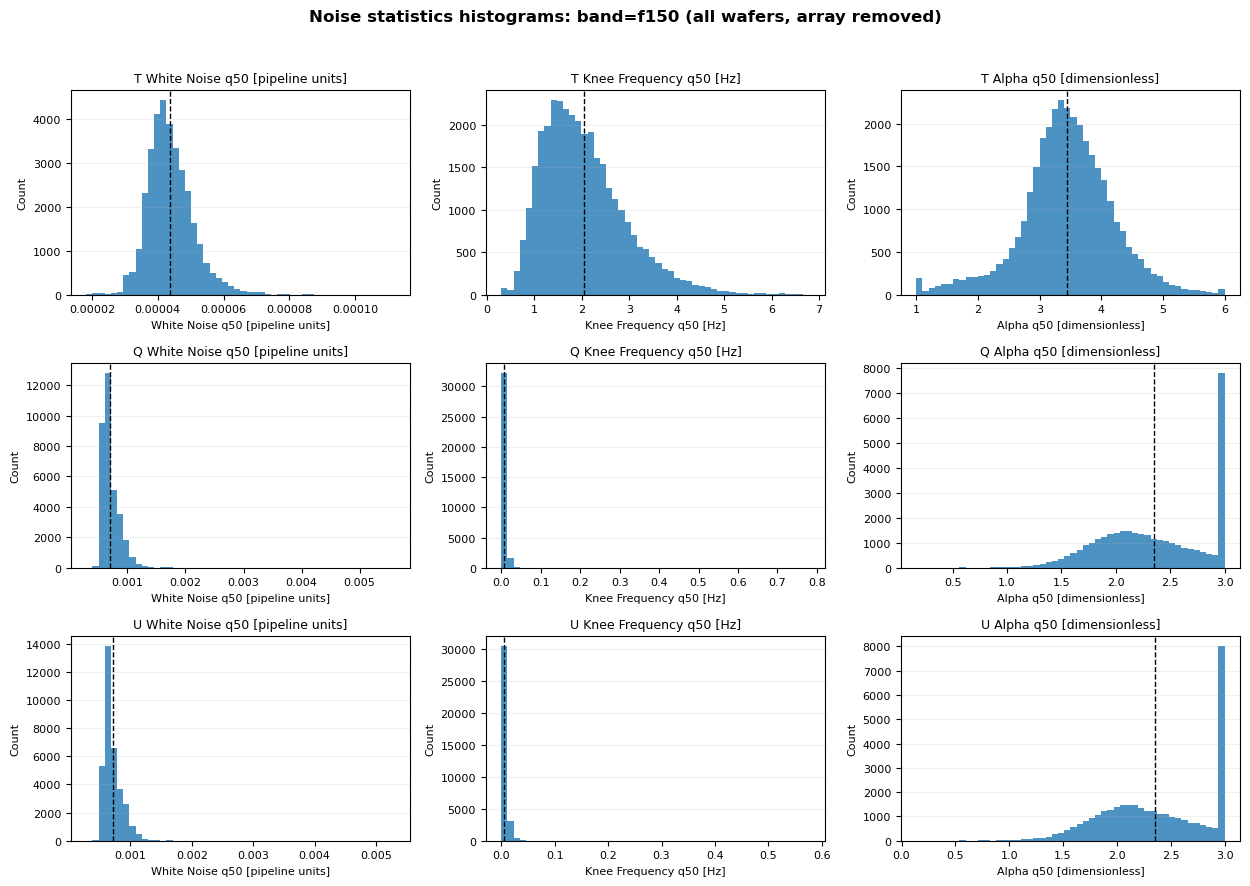

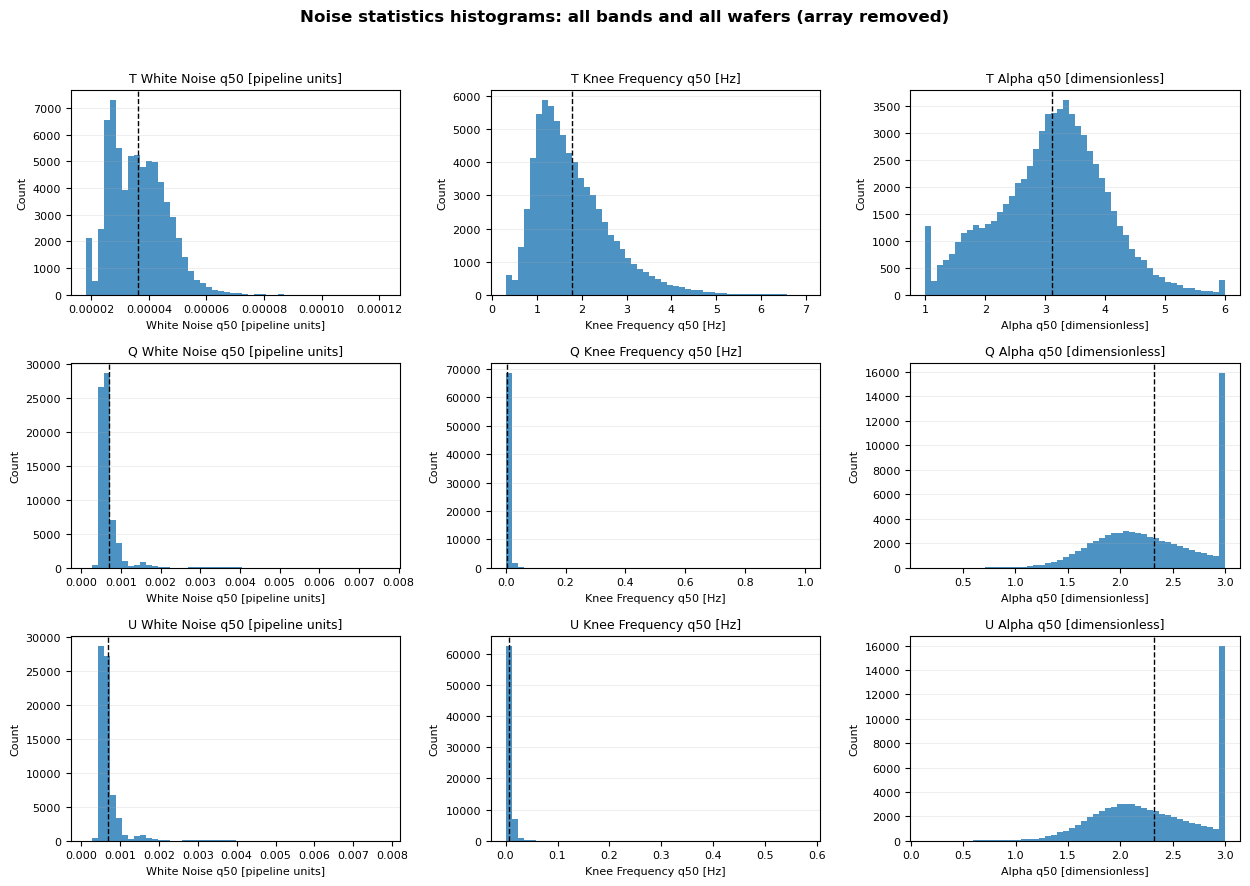

Saved noise histogram figures (array removed).


In [10]:
# --- Noise statistics histograms: wafer-band, band, all (array removed) ---
import math

def plot_noise_hist_grid(sub_df, title, save_path):
    plot_metrics = [m for m in noise_metrics if m[0] != 'array_noise']
    n_metrics = len(plot_metrics) * len(pols)
    n_cols = min(3, n_metrics)
    n_rows = int(math.ceil(n_metrics / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.0 * n_rows), squeeze=False)
    idx = 0
    for pol in pols:
        for metric, label in plot_metrics:
            col = f'noise_{pol}_{metric}'
            r, c = divmod(idx, n_cols)
            ax = axes[r][c]
            values = sub_df[col].to_numpy()
            values = values[np.isfinite(values)]
            if values.size == 0:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
            else:
                ax.hist(values, bins=50, alpha=0.8, edgecolor='none')
                ax.axvline(np.mean(values), color='k', linestyle='--', linewidth=1)
            ax.set_title(f'{pol} {label}', fontsize=9)
            ax.set_xlabel(label, fontsize=8)
            ax.set_ylabel('Count', fontsize=8)
            ax.tick_params(labelsize=8)
            ax.grid(alpha=0.2, axis='y')
            idx += 1

    for j in range(idx, n_rows * n_cols):
        r, c = divmod(j, n_cols)
        axes[r][c].set_visible(False)

    fig.suptitle(title, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

wafer_band_groups = sorted(df_noise.groupby(['wafer', 'band']).groups.keys(), key=lambda x: (x[1], x[0]))
for wafer, band in wafer_band_groups:
    sub = df_noise[(df_noise['wafer'] == wafer) & (df_noise['band'] == band)]
    title = f'Noise statistics histograms: wafer={wafer}, band={band} (array removed)'
    save_path = output_dir / f'noise_stats_hists_wafer_{wafer}_band_{band}.png'
    plot_noise_hist_grid(sub, title, save_path)

band_values = sorted(df_noise['band'].dropna().unique())
for band in band_values:
    sub = df_noise[df_noise['band'] == band]
    title = f'Noise statistics histograms: band={band} (all wafers, array removed)'
    save_path = output_dir / f'noise_stats_hists_band_{band}.png'
    plot_noise_hist_grid(sub, title, save_path)

plot_noise_hist_grid(
    df_noise,
    'Noise statistics histograms: all bands and all wafers (array removed)',
    output_dir / 'noise_stats_hists_all_wafers_all_bands.png',
)

print('Saved noise histogram figures (array removed).')
